# Where does a coding ban live inside Qwen3-8B? Demo of `method.py`

This notebook demonstrates the **internal-locus experiment** (iteration 3) on **Qwen3-8B** (pinned revision `b968826d`, thinking off, T = 1.0, decoder linears in FP8 W8A8). It is a cell-by-cell walk through the artifact's `method.py`, with explanations between the cells.

**The question.** Ask Qwen3-8B for a weighted shortest path and it writes Dijkstra's algorithm. Add *"Do not use Dijkstra's algorithm for this task."* and it switches to Bellman-Ford/SPFA most of the time. Where in the network does that prohibition act? The experiment tests four candidate answers. Each test runs beside a baseline under **common random numbers** (CRN): every arm reuses the same random draws in the same slot `(task, template, k)`, so arms can be compared slot by slot.

| Claim | What was tested | Verdict (full run) |
|---|---|---|
| **C2d**: a task-general *prohibition direction* `v` | **ADD** `v` (the leave-one-task-out mean ban-minus-twin displacement at blocks 12–23) into a neutral "twin" prompt, or **SUBTRACT** it from the ban prompt; compare with 3 norm-matched random directions | **DISCONFIRMED** |
| **C2e**: a *locus* inside the ban that decides which algorithm gets written | L2 decoders of default-vs-other on residual states (blocks 8–28, generated tokens 1–8 and 16) against text controls and a within-template permutation null | **no locus** |
| **C2f**: three ban-attending heads | mean-ablation of L21H17, L26H21, L26H25 against layer-matched random heads | **NOT SUPPORTED** |
| **0g**: Qwen-Scope SAEs transfer to the instruct model | fraction of CE recovered (FR_zero) in a 2×2 model × text design | frozen rule **PASS** (a lenient rule) |

Six tasks were sampled:

- path tasks **T1** (grid path, default BFS) and **T2** (weighted shortest path, default Dijkstra);
- bench tasks **T03** (k-th smallest, full sort), **T04** (substring search, naive window), **T06** (find duplicate, hash set) and **T05** (two-sum, hash map).

Each task has 5 ban wordings (templates W1–W5).

**What runs here and what does not.** The GPU stages of `method.py` do the heavy lifting: they sample 7,300 programs from the 16 GB model under steering hooks, extract hidden states and splice in SAEs. That needs an FP8-capable GPU and about 3.5 GPU-hours. Their code is shown verbatim below; set `STAGE` in the config cell to run one inside the original repository.

This notebook **executes** the CPU **`analyze` stage for C2d**, using the artifact's own `src/analysis` code, on a curated subset of the labelled samples. The subset is **100 CRN slots**: tasks T2 and T03, templates W1–W5, slots k = 0–9. Each slot carries the mechanism label of every steering arm. From these it recomputes:

- avoidance per arm;
- the ADD-vs-random exact McNemar tests;
- where each arm lands;
- the SUBTRACT deltas;
- ADD's rank among 15 random directions;
- the C2d verdict.

It then redraws the artifact's figures 1, 2, 3 and 9. The analysis itself takes seconds.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import sys
import time
from pathlib import Path

ROOT = Path.cwd()  # notebook: there is no __file__; the folder the notebook runs in plays the artifact root
sys.path.insert(0, str(ROOT / "src"))

from loguru import logger  # noqa: E402

# from cfg import (RESULTS_DIR, SAMPLED_TASKS, read_json, read_jsonl, set_ram_limit, setup_logging,  # noqa: E402
#                  utc_now, write_json)
# ^ the notebook runs without the repository's src/ package: these names are defined in the src/cfg.py cell below

# imports of the src/ modules copied below (cfg.py, analysis/common.py, analysis/c2d.py, analysis/run_all.py)
import hashlib
import json
import math
import os
import re
import resource
from collections import Counter
from datetime import datetime, timezone
from typing import Any, Iterable

import numpy as np
from scipy.stats import binom

# notebook additions: tables and figures
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/experiment-17/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

sub = data["metadata"]["demo_subset"]
print(data["metadata"]["method_name"], "|", data["metadata"]["model"])
print(f"{len(data['datasets'][0]['examples'])} CRN slots in '{data['datasets'][0]['dataset']}': tasks {sub['tasks']}, "
      f"templates {sub['templates']}, slots k {sub['slots_k'][0]}-{sub['slots_k'][-1]}")
ex0 = data["datasets"][0]["examples"][0]  # one CRN slot: the ban prompt and the label of every arm sampled on it
print("\n" + ex0["input"][:330] + " ...\n")
print({k[len("predict_"):]: v for k, v in ex0.items() if k.startswith("predict_")})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Where in Qwen3 a coding ban lives (iteration 3, internal locus) | Qwen/Qwen3-8B @ b968826d9c46dd6066d109eabc6255188de91218
100 CRN slots in 'c2d_arms': tasks ['T2', 'T03'], templates ['W1', 'W2', 'W3', 'W4', 'W5'], slots k 0-9

task=T2 template=W1 slot k=0. Ban prompt: Do not use Dijkstra's algorithm for this task.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a ...

{'ADD_a0p5': 'dijkstra|pass', 'ADD_a1p0': 'bf_spfa|fail', 'ADD_a2p0': 'dijkstra|pass', 'BAN': 'bf_spfa|pass', 'NEUTRAL': 'dijkstra|pass', 'RAND9001_a1p0': 'dijkstra|pass', 'RAND9001_a2p0': 'dijkstra|pass', 'RAND9002_a1p0': 'dijkstra|pass', 'RAND9002_a2p0': 'bf_spfa|fail', 'RAND9003_a1p0': 'dijkstra|pass', 'RAND9003_a2p0': 'dijkstra|pass', 'RAND9004_a

## Configuration

Every tunable parameter is set here.

**Executed analysis (CPU).**

- `N_BOOT`, `N_JS_PERM` and `N_TASK_BOOT` set the sizes of the bootstrap and permutation nulls.
- `TASKS` and `N_SLOTS` choose which part of the demo data is analysed. The demo data holds T2 and T03 at slots k 0–9. The full run analysed all 6 tasks, with BAN, NEUTRAL and SUB_plain on k 0–19, which gives N = 100 per arm.

**Original GPU pipeline.** `STAGE`, `MINUTES` and `OPTIONAL_MINUTES` are the command-line arguments of `method.py`; `N_PERM_*` and `EXTRA_SEEDS` are constants of its stages. They only take effect when `STAGE` is set and the notebook runs inside the artifact's repository on a GPU machine (see `reproducibility.md` there).

In [5]:
# ---- C2d analysis executed in this notebook (CPU) ----
TASKS = ("T2", "T03")   # tasks to analyse (demo data: T2, T03; full run: SAMPLED_TASKS = T2, T1, T03, T04, T06, T05)
N_SLOTS = 10            # use CRN slots k = 0 .. N_SLOTS-1 of every template (demo data: k 0-9; full run: k 0-19)
N_BOOT = 2000           # slot-bootstrap replicates of each SUBTRACT delta (analysis.common.boot_mean_diff; original 2000)
N_JS_PERM = 1000        # permutations of the landing-JS null (analysis.c2d.js_null; original 1000)
N_TASK_BOOT = 5000      # task-bootstrap replicates of the pooled SUBTRACT delta (analysis.c2d.run_c2d; original 5000)

# ---- original GPU pipeline (method.py); only used when STAGE is set ----
STAGE = None            # None = skip; else one of: prompts, gpu1, label, commit2, gpu2, s8c, gpu3, c2e, zerog, analyze
MINUTES = 60.0          # --minutes: deadline for required work, from now (method.py default 60)
OPTIONAL_MINUTES = 0.0  # --optional-minutes: extra time allowed for optional arms (method.py default 0)
N_PERM_PATH = 500       # C2e within-template permutations for T1/T2 (original 500)
N_PERM_BENCH = 200      # C2e permutations for bench tasks and the archive-pooled secondary analysis (original 200)
EXTRA_SEEDS = list(range(9004, 9016))  # exploratory random-direction seeds of stage gpu3 (original 9004-9015)

## 1. Shared constants and utilities: `src/cfg.py`

`method.py` imports its paths and helpers from `src/cfg.py`, and so does every analysis module. The cell below copies the parts of that module this notebook uses. Two changes: `ROOT` is the notebook's working folder, and the folder-creation loop only creates the three output folders the demo writes (`results/`, `figures/`, `logs/`).

Conventions:

- **Block l** is decoder block l (0-based).
- **S** is the task-specification span of the prompt.
- **R = P − 1** is the last prompt position.
- **Generated position k** is the state whose *input* is generated token k.

**Templates W1–W5** are the five ban wordings, where `{X}` names the default algorithm. Each has a **neutral twin**: the same sentence with a concrete noun `{N}` in place of `X`, padded to the same token length. The twin keeps the prohibition frame but bans nothing relevant.

`DEFAULT` gives the algorithm each task elicits without a ban. A program *avoids* when its mechanism label is not that default.

In [6]:
"""Shared constants, paths and small utilities for the iteration-3 internal-locus artifact.

Conventions (also stated in README.md and method_out.json):
- BLOCK l = decoder block l (0-based); its output is HF hidden_states[l + 1]. Saved 'block l' states are block-l
  outputs. exp8 c5.json and exp12 use 'layer l = hidden_states[l]' (= output of block l - 1); indices are mapped
  explicitly wherever those numbers are compared.
- SPEC positions S = [p1, spec_end): from the first token of 'Task:' to the last token of the user message
  (the chat tail '<|im_end|>\\n<|im_start|>assistant\\n<think>\\n\\n</think>\\n\\n' excluded). R = P - 1.
- Generated position k (1-based) = absolute position P + k - 1, where generated token k is the INPUT; the state
  there predicts token k + 1.
- CRN slot = (task, template, k); uniforms u_stream(task, template, k) are identical in every arm.
"""
# (imports of src/cfg.py: see the imports cell)

ROOT = Path.cwd()  # notebook (original: Path(__file__).resolve().parents[1], the artifact root)
INPUTS = ROOT / "inputs"
E8 = INPUTS / "exp8"
E11 = INPUTS / "exp11"
E12 = INPUTS / "exp12"
E9 = INPUTS / "exp9"
E7 = INPUTS / "exp7"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
PROMPTS_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
TOKEN_DIR = DATA_DIR / "token_ids"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
DIR_DIR = ROOT / "directions"
STATES_DIR = ROOT / "states"
PRED_DIR = ROOT / "predictions"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR):  # notebook: only the folders the demo writes (original: all of the above)
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_MODEL_ID = "Qwen/Qwen3-8B-Base"
SAE_REPO = "Qwen/SAE-Res-Qwen3-8B-Base-W64K-L0_50"
N_LAYERS = 36
D_MODEL = 4096
N_HEADS = 32
HEAD_DIM = 128
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
# Quantisation actually used (deviation F2; the 16 GB RTX 2000 Ada cannot hold the 16.4 GB of bf16 weights):
QUANT = "fp8_e4m3_w8a8_dynamic(per-output-channel weight scales, per-token activation scales; lm_head/embeddings/norms bf16)"


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
        if snaps.exists():
            cands = sorted(snaps.iterdir())
            if cands and revision is None:
                return str(cands[-1])
    return model_id


# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
ALL_TASKS = PATH_TASKS + BENCH_TASKS  # 14 tasks: the direction is built from all of them
SAMPLED_TASKS = ("T2", "T1", "T03", "T04", "T06", "T05")  # sampling order (fallback F3: whole tasks in this order)
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
           "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
           "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp"}
EXP8_TASK = {"T1": "t1", "T2": "t2"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."  # exp7 frozen padding rule: neutral segment + d x ' .' so the twin has the ban's token length

# ------------------------------------------------------------------------------------------------ design
V_BLOCKS = list(range(12, 24))          # blocks whose outputs are edited (exp8 band B2)
SAVE_BLOCKS = list(range(8, 29))        # blocks saved for diagnostics / decoders
ALPHAS_ADD = (1.0, 2.0, 0.5)
ALPHAS_RAND = (1.0, 2.0)
RAND_SEEDS = (9001, 9002, 9003)
HEAD_TARGET = [(21, 17), (26, 21), (26, 25)]
HEAD_RAND_SEEDS = (7101, 7102, 7103)
N_PER_TEMPLATE_FULL = 20                # k 0-19 x 5 templates = 100
N_PER_TEMPLATE_HALF = 10                # k 0-9 x 5 templates = 50
BATCH = 20                              # every sampled batch has exactly 20 rows (two 10-slot blocks or one 20-slot)
GEN_POSITIONS = [1, 2, 3, 4, 5, 6, 7, 8, 16]
JUDGE_CAP_USD = 0.40  # raised from the plan's 0.20 (logged deviation): T2 ban programs often leave runtime+AST unresolved
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


# (container_ram_gb, detect_cpus, sha256_*, stable_seed, append_jsonl, write_jsonl, cap_first, rel: not used here)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))

## 2. The orchestrator: `method.py`

`method.py` runs the experiment as resumable stages, one per command-line call. The order used for the reported run (from `reproducibility.md`):

| Stage | What it does | Device, approx. time |
|---|---|---|
| `prompts` | S1: 140 ban prompts (14 tasks × W1–W5) and their token-aligned neutral twins | CPU, 1 min |
| `gpu1` | S2 direction `v`, GPU unit tests, hash-chained commit #1 of the decision rules, U7 engine check, S5 ban-free arms | GPU, 30 min |
| `label` | labels every sampled program by mechanism (runtime trace → AST → blind LLM judge only on disagreement), running alongside the sampling stages | CPU |
| `commit2` | S6 summaries, ADD-landing forecasts, commit #2 (before any ban-condition sample) | CPU, < 1 min |
| `gpu2` | S7 ban arms (BAN, SUB, head ablation, W4 top-up) and S8 teacher-forced states | GPU, 55 min |
| `c2e` | C2e locus decoders | GPU, 20 min |
| `zerog` | 0g SAE transfer (base model in a separate load) | GPU, 45 min |
| `gpu3` | U1b, batch-1 state re-extraction, exploratory random directions, C2e extension | GPU, 30 + 10 min |
| `s8c` | batch-1 re-extraction of the 5c (geometry) states | GPU, 15 min |
| `analyze` | S9: every CPU analysis, figures, `method_out.json` | CPU, 6 min |

The six code cells of this section are `method.py` verbatim, split at its function boundaries. The only edits: `EXTRA_SEEDS` and the C2e permutation counts are read from the config cell. The functions import the repository's `src/` modules (`engine`, `sampling`, `direction`, …) lazily inside their bodies, so *defining* them here needs neither a GPU nor those modules; *calling* them needs both.

### Stage `gpu1`

1. Load Qwen3-8B with FP8 W8A8 linears (`engine.load_model`).
2. Build the leave-one-task-out prohibition direction `v` and the norm-matched random directions (`direction.stage_direction`).
3. Run the GPU unit tests, which check that:
   - sampling under CRN is deterministic;
   - ADD with α = 0 reproduces the twin token for token;
   - the realised displacement along `v` equals α·n;
   - SUB leaves no component along `v`;
   - the position convention holds.
4. Hash-chain the frozen decision rules (commit #1).
5. **U7:** reproduce the earlier exp8 result with its prompts and random keys (T2 ban → 2/20 Dijkstra, twin → 20/20). This validates the FP8 engine.
6. Sample the **S5 ban-free arms** (NEUTRAL, ADD α 1/2 (+0.5), RAND α 1/2) on the neutral twin. Whole tasks go in `SAMPLED_TASKS` order, in 20-row CRN batches, until the deadline.

In [7]:
"""Where in Qwen3-8B a coding ban lives -- orchestrator.

Stages (each resumable; see README.md):
  prompts   S1 (CPU)                     ban prompts + token-aligned neutral twins, 14 tasks x W1-W5
  gpu1      S2 + GPU unit tests + commit #1 + U7 + S5 (ban-free arms) + C2f head means
  label     label worker (CPU): labels every raw sample as it appears (exp8 suite for T1/T2, exp11 bench label_one)
  commit2   S6 (CPU): S5 summaries, ADD-landing forecast, commit #2
  gpu2      S7 (ban arms, SUB, heads, W4 top-up) + S8 state extraction
  zerog     0g SAE transfer (GPU, base model in a separate load)
  analyze   S9 analyses (C2d, C2e, C2f, 0g report, 5a, 5c) + figures + method_out.json
"""


def gpu1(deadline: float, optional_until: float) -> None:
    import torch

    from direction import stage_direction
    from engine import load_model
    from gpu_tests import run_gpu_tests
    from prereg import write_commit1
    from prompts import load_prompts
    from sampling import TaskContext, run_batch, run_task_phase, s5_batches

    torch.cuda.set_per_process_memory_fraction(0.97, 0)
    tok, model = load_model()
    prompts = load_prompts()
    if not (RESULTS_DIR / "direction.json").exists():
        stage_direction(model)
    if not (RESULTS_DIR / "unit_tests_gpu.json").exists():
        res = run_gpu_tests(model, tok, prompts)
        if not res["all_pass"]:
            logger.error("GPU unit tests failed -- see results/unit_tests_gpu.json")
            raise SystemExit(2)
    if not (ROOT / "predictions" / "commit1.json").exists():
        c = write_commit1()
        logger.info(f"commit #1: {len(c['chain'])} files hash-chained")
    # U7 engine validation against exp8 (T2, exp8 frozen prompts and exp8 uniform keys ('beh', 't2', w, s))
    raw = read_jsonl(ROOT / "data" / "samples_raw.jsonl")
    if not any(r.get("block_id", "").startswith("U7") for r in raw):
        ctx = TaskContext(model, tok, prompts, "T2")
        for arm in ("BAN", "NEUTRAL"):
            rows = run_batch(ctx, "W1", [(arm, list(range(20)))], f"U7:T2:W1:{arm}", ukey=("beh", "t2"),
                             arm_prefix="U7_")
            logger.info(f"U7 {arm}: {len(rows)} rows sampled with exp8 keys")
    # S5 required arms, whole tasks in the frozen order
    for t in SAMPLED_TASKS:
        n = run_task_phase(model, tok, prompts, t, s5_batches(), "S5", deadline=deadline)
        logger.info(f"S5 {t}: {n} new batches")
    # optional S5 arms (RAND alpha 2 for seeds 9002/9003, then ADD alpha 0.5) while time allows
    for t in SAMPLED_TASKS:
        if time.time() > optional_until:
            break
        run_task_phase(model, tok, prompts, t, s5_batches(optional=True), "S5", deadline=optional_until)
    write_json(RESULTS_DIR / "gpu1_done.json", {"utc": utc_now()})

### Stage `s8c` (and `EXTRA_SEEDS`)

Under FP8, states taken from 20-row teacher-forcing batches carry 4–10% row-position noise, because GEMM tiling depends on the batch shape. `s8c` therefore re-extracts the states of every non-ban arm at **batch 1**, so that every point in the descriptive geometry analysis (5c) comes from the same extraction mode.

`EXTRA_SEEDS` is the list of the 12 exploratory random directions that stage `gpu3` samples. It now lives in the config cell.

In [8]:
# EXTRA_SEEDS = list(range(9004, 9016))  -> set in the config cell


def s8c() -> None:
    """Re-extract the 5c states of every non-ban/neutral arm at batch 1, so all 5c points share one extraction mode
    (BAN/NEUTRAL were re-extracted at batch 1 in gpu3; mixing batch-20 and batch-1 states would add a systematic
    row-position offset between arms)."""
    from engine import load_model
    from gpu2 import _raw_by_arm
    from prompts import load_prompts
    from states import BLOCKS_5C, save_arm

    tok, model = load_model()
    prompts = load_prompts()
    t0 = time.time()
    for (t, arm), rows in sorted(_raw_by_arm().items()):
        if t not in SAMPLED_TASKS or arm in ("BAN", "NEUTRAL", "BAN_TOPUP") or arm.startswith(("U7", "RAND90")) \
                and arm not in ("RAND9001_a1.0", "RAND9002_a1.0", "RAND9003_a1.0", "RAND9001_a2.0", "RAND9002_a2.0",
                                "RAND9003_a2.0"):
            continue
        kind = "twin" if (arm.startswith("ADD") or arm.startswith("RAND")) else "ban"
        save_arm(model, prompts, t, arm, rows, tag=f"5c_{t}_{arm}", blocks=BLOCKS_5C, full=False, prompt_kind=kind,
                 bs=1, overwrite=True)
    write_json(RESULTS_DIR / "s8c_done.json", {"utc": utc_now(), "seconds": time.time() - t0})

### Unit test U1b

U1b checks the three assumptions the CRN design rests on:

- **(a)** When sampling 20 rows at once, two rows given identical uniforms produce identical tokens, whatever their batch positions. Coupling across arms is therefore exact.
- **(b)** Teacher forcing at batch 1 is bit-exact and depends only on the prefix.
- **(c)** Teacher forcing in a 20-row batch is *not* bit-exact; the test measures the relative L2 difference at block 28.

Reported in `results/unit_tests_u1b.json`:

- (a) holds;
- (b) gives max |Δ| = 0;
- (c) gives about 10%.

This is why the C2e states were re-extracted at batch 1.

In [9]:
def u1b(model, tok, prompts) -> None:
    """U1b: (a) decode is row-position independent: rows with identical prefill and identical uniforms placed at
    different batch positions give identical tokens; (b) teacher forcing at batch 1 is deterministic and depends only on
    the prefix; (c) teacher forcing in a 20-row batch is NOT (FP8 GEMM tiling), quantified."""
    import numpy as np

    from engine import forward_capture, sample, u_stream
    from sampling import TaskContext

    ctx = TaskContext(model, tok, prompts, "T2")
    pre = ctx.clean_prefill("W1", "twin")["pre"]
    us = [u_stream("u1b", j % 10) for j in range(20)]  # row j and row j+10 share uniforms
    res = sample(model, [{"pre": pre, "us": us}], max_new=96)
    same = [res[j]["token_ids"] == res[j + 10]["token_ids"] for j in range(10)]
    pr = prompts[("T2", "W1", "ban")]
    ids = pr["ids"] + [73594, 12669, 198]
    P = pr["P"]
    a = forward_capture(model, [ids], [20, 28], [P - 1, P])
    b = forward_capture(model, [ids], [20, 28], [P - 1, P])
    batch = forward_capture(model, [ids] * 20, [20, 28], [P - 1, P])
    d1 = float((a["states"][28] - b["states"][28]).abs().max())
    xs = batch["states"][28]
    rel = float(((xs - xs[0:1]).norm(dim=-1) / xs[0:1].norm(dim=-1)).max())
    rel_b1_vs_batch = float(((xs - a["states"][28]).norm(dim=-1) / a["states"][28].norm(dim=-1)).max())
    out = {"decode_rows_identical_given_same_uniforms": all(same), "n_pairs": len(same),
           "batch1_repeat_max_abs_diff_block28": d1,
           "batch20_identical_rows_max_rel_l2_diff_block28": rel,
           "batch20_vs_batch1_max_rel_l2_diff_block28": rel_b1_vs_batch,
           "note": "(a) decode at M=20 is position independent, so CRN coupling across arms is exact; (b)/(c) teacher "
                   "forcing must run at batch 1 for states to depend only on the prefix"}
    write_json(RESULTS_DIR / "unit_tests_u1b.json", out)
    logger.info(f"U1b: {out}")

### Stage `gpu3`

This stage is exploratory and sits outside the frozen rules. In order, it:

- runs U1b;
- re-extracts the S8 states at batch 1;
- runs the conditional causal patch, but only for tasks where C2e found a locus (none did, so the patch never ran);
- extracts states at generated positions 24–96 (the C2e extension);
- samples the 12 `EXTRA_SEEDS` random directions at α = 1 on T2, T1 and T03 (CRN slots k 0–9).

The last step places ADD within a distribution of 15 random directions. The analysis below recomputes that distribution for T2 and T03.

In [10]:
def gpu3(deadline: float) -> None:
    """EXPLORATORY (not in the frozen rules): 12 more random directions at alpha 1 on T2, T1, T03 -- where does ADD's
    avoidance sit in the distribution of random-direction effects? Same construction, CRN slots k 0-9."""
    import torch

    from engine import load_model
    from prompts import load_prompts
    from sampling import K10, run_task_phase

    tok, model = load_model()
    prompts = load_prompts()
    if not (RESULTS_DIR / "unit_tests_u1b.json").exists():
        u1b(model, tok, prompts)
    # S8 re-extraction at batch 1 (the plan's specification; see unit_tests_u1b.json and README)
    if not (RESULTS_DIR / "s8_batch1_done.json").exists():
        from gpu2 import _raw_by_arm
        from states import stage_states_b1

        stage_states_b1(model, prompts, _raw_by_arm(), list(SAMPLED_TASKS))
        write_json(RESULTS_DIR / "s8_batch1_done.json", {"utc": utc_now()})
    # conditional causal patch (9.2): only for tasks where C2e found a locus (k*, L*)
    c2e_p = RESULTS_DIR / "c2e.json"
    if c2e_p.exists():
        from patch import analyse_patch, run_patch

        for t, v in read_json(c2e_p)["primary"].items():
            if v.get("locus") and not (RESULTS_DIR / f"c2e_patch_{t}.json").exists():
                run_patch(model, tok, prompts, t, v["locus"]["k"], v["locus"]["block"])
                analyse_patch(t)
    # exploratory C2e extension: states at generated positions 24-96 (the frozen window ends before the fork)
    from c2e_ext import extract, run_all_ext

    try:
        extract(model, prompts)
    except Exception as e:  # noqa: BLE001 - exploratory; never block the remaining stage
        logger.exception(f"C2e extension extraction failed: {e}")
    batches = [[(f"RAND{a}_a1.0", K10), (f"RAND{b}_a1.0", K10)] for a, b in zip(EXTRA_SEEDS[::2], EXTRA_SEEDS[1::2])]
    for t in ("T2", "T1", "T03"):
        if time.time() > deadline:
            break
        n = run_task_phase(model, tok, prompts, t, batches, "X1", deadline=deadline)
        logger.info(f"X1 extra random directions {t}: {n} batches")
    torch.cuda.empty_cache()
    try:
        if not (RESULTS_DIR / "c2e_extension.json").exists():
            run_all_ext()
    except Exception as e:  # noqa: BLE001
        logger.exception(f"C2e extension decoders failed: {e}")
    write_json(RESULTS_DIR / "gpu3_done.json", {"utc": utc_now()})

### Stage `c2e`

For each sampled task, `analysis.c2e.run_task` fits L2 logistic decoders of *default vs other* to the batch-1 teacher-forced residual states of the ban samples. The states come from blocks 8–28, at the S-mean, at R, and at generated tokens 1–8 and 16.

The decoders are compared against:

- three written-text controls of matched or greater capacity:
  - Ta, token one-hots;
  - Tb, layer-0 embeddings reduced to PCA-64;
  - Tc, exact prefix match;
- the template-only decoder;
- a within-template permutation null with a layer-max statistic.

A *locus* needs a state decoder that beats every text control by 0.10 and clears the null's 95th percentile. The permutation counts come from the config cell (`N_PERM_PATH`, `N_PERM_BENCH`).

In [11]:
def c2e_stage(deadline: float) -> None:
    """9.2 C2e decoders on the GPU (primary per sampled task; secondary archive-pooled analysis for T1/T2)."""
    from analysis.c2e import run_task

    out_p = RESULTS_DIR / "c2e.json"
    res = read_json(out_p) if out_p.exists() else {"primary": {}, "secondary_archive_pooled": {}}
    for t in SAMPLED_TASKS:
        if t in res["primary"] or time.time() > deadline:
            continue
        t0 = time.time()
        res["primary"][t] = run_task(t, n_perm=N_PERM_PATH if t in ("T1", "T2") else N_PERM_BENCH)  # original: 500 / 200
        res["primary"][t]["seconds"] = time.time() - t0
        write_json(out_p, res)
        logger.info(f"C2e {t}: {res['primary'][t].get('status')} locus={res['primary'][t].get('locus')} "
                    f"({time.time() - t0:.0f}s)")
    for t in ("T1", "T2"):
        if t in res["secondary_archive_pooled"] or time.time() > deadline:
            continue
        r = run_task(t, n_perm=N_PERM_BENCH, archive=True)  # original: 200
        r["label"] = "secondary, archive-pooled (exp8 arm a + exp12 fresh pool; blocks 8-28 every 2nd block)"
        res["secondary_archive_pooled"][t] = r
        write_json(out_p, res)
    res["n_perm"] = {"T1": N_PERM_PATH, "T2": N_PERM_PATH, "bench": N_PERM_BENCH, "archive": N_PERM_BENCH}
    write_json(out_p, res)

### `main()`: command-line dispatch

`main()` handles the command line: it reads `stage --minutes M --optional-minutes O`, turns the minutes into wall-clock deadlines, and calls the stage. CPU stages get a 24 GB RAM cap; GPU stages run uncapped, because the CUDA driver reserves a large virtual address space. The `analyze` stage runs `analysis.run_all.run_all()`; section 3 executes the C2d part of it on the demo data.

In [12]:
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage")
    ap.add_argument("--minutes", type=float, default=60.0, help="deadline for required work (from now)")
    ap.add_argument("--optional-minutes", type=float, default=0.0, help="extra time allowed for optional arms")
    a = ap.parse_args()
    setup_logging(a.stage)
    if a.stage in ("prompts", "label", "commit2", "analyze"):
        set_ram_limit(24)  # never on CUDA processes: the driver reserves a large virtual address space
    now = time.time()
    deadline = now + a.minutes * 60
    optional_until = now + a.optional_minutes * 60
    logger.info(f"stage {a.stage}: deadline in {a.minutes:.0f} min, optional until +{a.optional_minutes:.0f} min")
    if a.stage == "prompts":
        from prompts import stage_prompts
        stage_prompts()
    elif a.stage == "gpu1":
        gpu1(deadline, optional_until)
    elif a.stage == "label":
        from label_worker import run_worker
        run_worker(follow=True, deadline=deadline)
    elif a.stage == "commit2":
        from analysis.commit2 import stage_commit2
        stage_commit2()
    elif a.stage == "gpu2":
        from gpu2 import gpu2
        gpu2(deadline, optional_until)
    elif a.stage == "s8c":
        s8c()
    elif a.stage == "gpu3":
        gpu3(deadline)
    elif a.stage == "c2e":
        c2e_stage(deadline)
    elif a.stage == "zerog":
        from zerog import stage_zerog
        stage_zerog(deadline)
    elif a.stage == "analyze":
        from analysis.run_all import run_all
        run_all()
    else:
        raise SystemExit(f"unknown stage {a.stage}")

### Running an original stage (optional)

`method.py` ends with `if __name__ == "__main__": logger.catch(reraise=True)(main)()`. Inside a notebook `__name__` is always `"__main__"`, so here that call is guarded by `STAGE` instead, and with the default `STAGE = None` nothing runs.

To run a stage, set `STAGE` and run the notebook from the artifact's folder in the repository, so that `src/` is importable (`sys.path` already includes `ROOT / "src"`). The stage also needs:

- the pinned environment (`pyproject.toml`);
- Qwen3-8B in the Hugging Face cache;
- a GPU with FP8 support (compute capability ≥ 8.9, ≥ 16 GB).

The command-line arguments are built from `MINUTES` and `OPTIONAL_MINUTES`.

In [13]:
if STAGE is not None:  # notebook stand-in for: python method.py STAGE --minutes MINUTES --optional-minutes OPTIONAL_MINUTES
    sys.argv = ["method.py", STAGE, "--minutes", str(MINUTES), "--optional-minutes", str(OPTIONAL_MINUTES)]
    logger.catch(reraise=True)(main)()  # original: if __name__ == "__main__": logger.catch(reraise=True)(main)()
else:
    print("STAGE = None: the GPU stages are not run here; section 3 runs the C2d analysis on the demo data.")

STAGE = None: the GPU stages are not run here; section 3 runs the C2d analysis on the demo data.


## 3. The `analyze` stage (S9) on the demo data

`run_all()` (in `src/analysis/run_all.py`) does four things in turn:

1. build one merged row per labelled program;
2. run every analysis;
3. render the figures;
4. write `method_out.json`.

This section runs its C2d part, unchanged, on the 100 demo slots.

### Analysis helpers: `src/analysis/common.py`

The module is copied verbatim; the only edit is that the bootstrap size reads `N_BOOT`. The helpers C2d relies on:

- **`shares(rows, task)`**: the behaviour summary of one arm.
  - *avoidance* = 1 − default/attempted, with a Wilson 95% CI;
  - the *landing* counter, i.e. which non-default algorithms were written;
  - the modal non-default algorithm.

  Programs labelled `invalid` or `disputed` count as not attempted.
- **`paired(rows_a, rows_b)`**: matches two arms on their shared CRN slots `(template, k)`.
- **`mcnemar_one_sided`**: an exact McNemar test on those pairs.
- **`holm`**: the Holm correction.
- **`boot_mean_diff`**: a slot bootstrap of a paired difference.
- **`js_divergence`**: compares two landing distributions (Jensen–Shannon, base 2).

`merged()` shows how the full pipeline joins `data/samples_raw.jsonl` with `data/labels.jsonl`. The demo has neither file, so the next section rebuilds the same rows from `data`.

In [14]:
"""Shared analysis helpers: merged sample rows, behaviour shares, exact paired tests, Holm, bootstraps."""
# (imports of src/analysis/common.py: see the imports cell; DATA_DIR, DEFAULT, read_jsonl, wilson_ci: src/cfg.py cell)

RAW = DATA_DIR / "samples_raw.jsonl"
LABELS = DATA_DIR / "labels.jsonl"
NOT_ATTEMPTED = ("invalid", "disputed")


def merged(drop_text: bool = True) -> list[dict[str, Any]]:
    labs = {r["key"]: r for r in read_jsonl(LABELS)}
    out = []
    for r in read_jsonl(RAW):
        k = f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"
        l = labs.get(k)
        row = {kk: vv for kk, vv in r.items() if not (drop_text and kk in ("text", "token_ids"))}
        row["key"] = k
        if l is not None:
            for f in ("label", "labeller_source", "passed", "valid", "runtime_label", "ast_label", "judge_label",
                      "fallback_label", "code_sha256"):
                row[f] = l.get(f)
            row["is_default"] = l["label"] == DEFAULT[r["task"]]
        out.append(row)
    return out


def rows_of(rows: list[dict[str, Any]], task: str, arm: str, ks: list[int] | None = None) -> list[dict[str, Any]]:
    return [r for r in rows if r["task"] == task and r["arm"] == arm and "label" in r
            and (ks is None or int(r["sample_id"]) in ks)]


def shares(rows: list[dict[str, Any]], task: str, disputed_as_default: bool = False) -> dict[str, Any]:
    """Behaviour summary of a set of labelled rows of one task."""
    x = DEFAULT[task]
    labs = []
    for r in rows:
        l = r["label"]
        if l == "disputed" and disputed_as_default:
            l = x
        labs.append(l)
    att = [l for l in labs if l not in NOT_ATTEMPTED]
    n_att = len(att)
    n_def = sum(l == x for l in att)
    nondef = [l for l in att if l != x]
    land = Counter(nondef)
    corr = Counter(r["label"] for r in rows if r["label"] not in NOT_ATTEMPTED and r["label"] != x and r.get("passed"))
    n = len(rows)
    av = 1 - n_def / n_att if n_att else float("nan")
    lo, hi = wilson_ci(n_att - n_def, n_att) if n_att else (float("nan"), float("nan"))
    modal = land.most_common(1)[0][0] if land else None
    pc = np.array(list(corr.values()), float)
    hill_cc = float(math.exp(-(pc / pc.sum() * np.log(pc / pc.sum())).sum())) if pc.sum() > 0 else 0.0
    return {"n": n, "n_attempted": n_att, "n_default": n_def, "n_nondefault": len(nondef),
            "avoidance": av, "avoidance_ci95": [lo, hi], "default_share": (n_def / n_att) if n_att else float("nan"),
            "landing": dict(land.most_common()), "modal_nondefault": modal,
            "modal_nondefault_n": land.most_common(1)[0][1] if land else 0,
            "landing_correct_only": dict(corr.most_common()), "hill_cc": hill_cc,
            "pass_rate": float(np.mean([bool(r.get("passed")) for r in rows])) if n else float("nan"),
            "other_share": (sum(l == "other" for l in labs) / n) if n else float("nan"),
            "invalid_share": (sum(l == "invalid" for l in labs) / n) if n else float("nan"),
            "disputed_share": (sum(l == "disputed" for l in labs) / n) if n else float("nan")}


def by_slot(rows: list[dict[str, Any]]) -> dict[tuple[str, int], dict[str, Any]]:
    return {(r["template"], int(r["sample_id"])): r for r in rows}


def avoided(r: dict[str, Any]) -> int | None:
    """1 = attempted and non-default, 0 = default, None = not attempted (invalid / disputed)."""
    if r["label"] in NOT_ATTEMPTED:
        return None
    return int(r["label"] != DEFAULT[r["task"]])


def mcnemar_one_sided(a: list[int], b: list[int]) -> dict[str, Any]:
    """Exact one-sided McNemar on paired binary outcomes: H1 P(a=1,b=0) > P(a=0,b=1)."""
    n10 = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    n01 = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = n10 + n01
    p = float(binom.sf(n10 - 1, n, 0.5)) if n > 0 else 1.0
    return {"n10": n10, "n01": n01, "n_pairs": len(a), "p_one_sided": p}


def mcnemar_two_sided(a: list[int], b: list[int]) -> dict[str, Any]:
    n10 = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    n01 = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = n10 + n01
    p = float(min(1.0, 2 * binom.cdf(min(n10, n01), n, 0.5))) if n > 0 else 1.0
    return {"n10": n10, "n01": n01, "n_pairs": len(a), "p_two_sided": p}


def holm(ps: list[float]) -> list[float]:
    m = len(ps)
    order = np.argsort(ps)
    adj = [0.0] * m
    run = 0.0
    for rank, i in enumerate(order):
        v = min(1.0, (m - rank) * ps[i])
        run = max(run, v)
        adj[i] = run
    return adj


def paired(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], fn=avoided) -> tuple[list[int], list[int]]:
    A, B = by_slot(rows_a), by_slot(rows_b)
    xs, ys = [], []
    for s in sorted(set(A) & set(B)):
        x, y = fn(A[s]), fn(B[s])
        if x is None or y is None:
            continue
        xs.append(x)
        ys.append(y)
    return xs, ys


# notebook: the n_boot default comes from the config cell (original: n_boot: int = 2000)
def boot_mean_diff(x: list[int], y: list[int], n_boot: int = N_BOOT, seed: int = 0) -> tuple[float, list[float]]:
    x_, y_ = np.asarray(x, float), np.asarray(y, float)
    if len(x_) == 0:
        return float("nan"), [float("nan"), float("nan")]
    d = x_ - y_
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), (n_boot, len(d)))
    bs = d[idx].mean(1)
    return float(d.mean()), [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a /= a.sum()
    b /= b.sum()
    m = (a + b) / 2

    def kl(u, v):
        msk = u > 0
        return float((u[msk] * np.log2(u[msk] / v[msk])).sum())
    return 0.5 * kl(a, m) + 0.5 * kl(b, m)

### Rebuild the labelled rows from the demo data (stands in for `merged()`)

Each demo example is one CRN slot `(task, template, k)`. Its `predict_<arm>` fields hold `"<mechanism label>|pass"` or `"…|fail"` for every arm sampled on that slot, written by `run_all.method_out`. Turning them back into rows gives exactly the fields the C2d code reads: `task`, `template`, `arm`, `sample_id = k`, `label`, `passed` and `is_default`. Arm names undo `run_all._san` (`ADD_a1p0` → `ADD_a1.0`). Only `TASKS` and slots `k < N_SLOTS` are kept.

| Arm | Prompt | Edit |
|---|---|---|
| `BAN` | named ban | none |
| `NEUTRAL` | neutral twin | none |
| `ADD_aα` | twin | `v` written in at the task-spec positions, blocks 12–23, with displacement = α × the ban's own displacement norm |
| `RAND<seed>_aα` | twin | a random direction with matched norm |
| `SUB_plain` | named ban | `v` projected out |

On T2 there are two extra SUB controls:

- `SUB_affine`: the projection anchored on the twin;
- `SUB_rand9001`: a random edit with SUB_plain's norm.

In [15]:
def rows_from_demo(data: dict[str, Any]) -> list[dict[str, Any]]:
    """Notebook stand-in for merged(): one labelled row per (task, template, arm, slot k) of the c2d_arms examples."""
    rows = []
    for e in data["datasets"][0]["examples"]:
        t, w, k = e["metadata_task"], e["metadata_template"], int(e["metadata_k"])
        if t not in TASKS or k >= N_SLOTS:
            continue
        for key, v in e.items():
            if not key.startswith("predict_"):
                continue
            label, ok = v.split("|")
            arm = re.sub(r"_a(\d+)p(\d+)$", r"_a\1.\2", key[len("predict_"):])  # undo run_all._san: ADD_a1p0 -> ADD_a1.0
            rows.append({"task": t, "template": w, "arm": arm, "sample_id": k, "key": f"{t}|{w}|{arm}|{k}",
                         "label": label, "passed": ok == "pass", "is_default": label == DEFAULT[t]})
    return rows


rows = rows_from_demo(data)
print(f"{len(rows)} labelled rows = {len({(r['task'], r['template'], r['sample_id']) for r in rows})} CRN slots x "
      f"{len({r['arm'] for r in rows})} arms")
# which algorithm each arm wrote (counts over the selected slots)
display(pd.crosstab([pd.Series([r["task"] for r in rows], name="task"), pd.Series([r["arm"] for r in rows], name="arm")],
                    pd.Series([r["label"] for r in rows], name="mechanism label")))

2500 labelled rows = 100 CRN slots x 26 arms


mechanism label     bf_spfa  dijkstra  full_sort  heapify_pop  other  \
task arm                                                               
T03  ADD_a0.5             0         0         41            0      0   
     ADD_a1.0             0         0         10            0      0   
     ADD_a2.0             0         0         15            0      0   
     BAN                  0         0          0            0      0   
     NEUTRAL              0         0         50            0      0   
     RAND9001_a1.0        0         0         38            0      0   
     RAND9001_a2.0        0         0          2            0      0   
     RAND9002_a1.0        0         0         15            0      0   
     RAND9002_a2.0        0         0         24            0      0   
     RAND9003_a1.0        0         0         32            0      0   
     RAND9003_a2.0        0         0         35            1      0   
     RAND9004_a1.0        0         0         50            0      0   
     RAND9005_a1.0        0         0         50            0      0   
     RAND9006_a1.0        0         0         35            0      0   
     RAND9007_a1.0        0         0         50            0      0   
     RAND9008_a1.0        0         0         50            0      0   
     RAND9009_a1.0        0         0         49            0      0   
     RAND9010_a1.0        0         0         15            0      0   
     RAND9011_a1.0        0         0         22            0      0   
     RAND9012_a1.0        0         0         50            0      0   
     RAND9013_a1.0        0         0         47            2      0   
     RAND9014_a1.0        0         0         15            0      0   
     RAND9015_a1.0        0         0         50            0      0   
     SUB_plain            0         0          0            1      4   
T2   ADD_a0.5             1        49          0            0      0   
     ADD_a1.0            21        28          0            0      1   
     ADD_a2.0             5        44          0            0      1   
     BAN                 45         5          0            0      0   
     NEUTRAL              0        50          0            0      0   
     RAND9001_a1.0        3        47          0            0      0   
     RAND9001_a2.0        5        45          0            0      0   
     RAND9002_a1.0       24        25          0            0      1   
     RAND9002_a2.0       37        13          0            0      0   
     RAND9003_a1.0       17        33          0            0      0   
     RAND9003_a2.0        3        47          0            0      0   
     RAND9004_a1.0       24        26          0            0      0   
     RAND9005_a1.0        0        50          0            0      0   
     RAND9006_a1.0        5        45          0            0      0   
     RAND9007_a1.0       31        18          0            0      1   
     RAND9008_a1.0       17        31          0            0      2   
     RAND9009_a1.0        2        47          0            0      1   
     RAND9010_a1.0        0        50          0            0      0   
     RAND9011_a1.0        5        44          0            0      1   
     RAND9012_a1.0        9        41          0            0      0   
     RAND9013_a1.0        0        50          0            0      0   
     RAND9014_a1.0        0        50          0            0      0   
     RAND9015_a1.0        4        46          0            0      0   
     SUB_affine          49         1          0            0      0   
     SUB_plain           40        10          0            0      0   
     SUB_rand9001         7        10          0            0     33   

mechanism label     quickselect  size_k_heap  
task arm                                      
T03  ADD_a0.5                 6            3  
     ADD_a1.0                 1           39  
     ADD_a2.0                 4           31  
     BAN            

### C2d analysis: `src/analysis/c2d.py`

The module is copied verbatim, with three edits:

- the size of the permutation null reads `N_JS_PERM`;
- the size of the task bootstrap reads `N_TASK_BOOT`;
- `run_c2d` takes the commit #2 landing forecasts from `data` instead of `predictions/c2d_landings.json`.

The **frozen decision rules** were hash-committed before any sample was drawn:

1. **Event gate (per task).** The named ban must actually work: avoidance ≥ 0.5 with ≥ 20 non-default programs. Only gated tasks enter the ADD denominator.
2. **ADD passes on a task** if, at α = 1 or 2, both of these hold:
   - ADD's avoidance beats *each* of the 3 norm-matched random directions. The test is a one-sided exact McNemar on CRN slots k 0–9, Holm-corrected over 3 controls × 2 alphas.
   - ADD's modal non-default program equals the ban's, i.e. it *lands* where the ban lands.
3. **Within random range.** At neither α does ADD's avoidance exceed the maximum over the random directions.
4. **SUBTRACT.** Δ = banned share under SUB_plain − banned share under BAN, paired over slots and bootstrapped. It is pooled over the tasks where the ban works, using a task bootstrap and a jackknife.
5. **Verdict.**
   - SUPPORTED iff ADD passes on ≥ 2/3 of the gated tasks *and* the pooled Δ ≥ 0.3 with CI lower bound > 0;
   - DISCONFIRMED iff ADD is within the random range on more than 1/3 of the tasks;
   - PARTIAL otherwise.

Three more functions:

- `js_null` tests landings: the Jensen–Shannon divergence between ADD's and the ban's landings, against a within-template permutation null.
- `exploratory_random_distribution` (outside the frozen rule) ranks ADD at α = 1 among all 15 random directions.
- `realised()` reads the logged edit norms. They are not in the demo data, so it returns `{}`.

In [16]:
"""9.1 C2d: is there an X-free, task-general prohibition direction? ADD (sufficiency on the neutral twin) against
norm-matched random directions under CRN, SUBTRACT (necessity on the ban prompt), landings, dose-response."""
# (imports of src/analysis/c2d.py: see the imports cell; analysis.common and cfg names: cells above)

K10 = list(range(10))


def is_default(r: dict[str, Any]) -> int | None:
    if r["label"] in NOT_ATTEMPTED:
        return None
    return int(r["label"] == DEFAULT[r["task"]])


def realised(task: str) -> dict[str, Any]:
    recs = [r for r in read_jsonl(DATA_DIR / "realised_norms.jsonl") if r["task"] == task]
    out: dict[str, Any] = {}
    for arm in sorted({r["arm"] for r in recs}):
        rs = [r for r in recs if r["arm"] == arm]
        blocks = sorted({int(b) for r in rs for b in r["disp_S_mean_norm"]})
        o = {"disp_S_mean_norm": {b: float(np.mean([r["disp_S_mean_norm"][str(b)] for r in rs])) for b in blocks},
             "disp_R_norm": {b: float(np.mean([r["disp_R_norm"][str(b)] for r in rs])) for b in blocks},
             "edit_norm_mean": {b: float(np.mean([r["edit_norm_mean"][str(b)] for r in rs if str(b) in
                                                  r["edit_norm_mean"]])) for b in range(12, 24)
                                if any(str(b) in r["edit_norm_mean"] for r in rs)}}
        if any("rel_err_along_u" in r for r in rs):
            o["rel_err_along_u_max"] = float(max(max(r["rel_err_along_u"].values()) for r in rs
                                                 if "rel_err_along_u" in r))
            o["target_norm_mean"] = {b: float(np.mean([r["target_norm_mean"][str(b)] for r in rs
                                                       if "target_norm_mean" in r])) for b in range(12, 24)}
        out[arm] = o
    return out


# notebook: the permutation-count default comes from the config cell (original: n: int = 1000)
def js_null(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], task: str, n: int = N_JS_PERM,
            seed: int = 0) -> dict[str, Any]:
    """JS(landing_a, landing_b) against a within-template arm-label permutation null of the non-default rows."""
    x = DEFAULT[task]
    A = [r for r in rows_a if r["label"] not in NOT_ATTEMPTED and r["label"] != x]
    B = [r for r in rows_b if r["label"] not in NOT_ATTEMPTED and r["label"] != x]
    obs = js_divergence(Counter(r["label"] for r in A), Counter(r["label"] for r in B))
    if not A or not B:
        return {"js": obs, "null_q95": None, "p": None}
    rng = np.random.default_rng(seed)
    pool = [(r["template"], r["label"], 0) for r in A] + [(r["template"], r["label"], 1) for r in B]
    temps = sorted({p[0] for p in pool})
    null = []
    for _ in range(n):
        ca: Counter = Counter()
        cb: Counter = Counter()
        for w in temps:
            items = [p for p in pool if p[0] == w]
            labs = [p[1] for p in items]
            side = rng.permutation([p[2] for p in items])
            for l, s in zip(labs, side):
                (ca if s == 0 else cb)[l] += 1
        null.append(js_divergence(ca, cb))
    null = np.array(null)
    return {"js": obs, "null_q95": float(np.nanquantile(null, 0.95)), "p": float(np.mean(null >= obs))}


def analyse_task(rows: list[dict[str, Any]], task: str, forecast: dict[str, Any] | None) -> dict[str, Any]:
    arms = sorted({r["arm"] for r in rows if r["task"] == task and "label" in r and not r["arm"].startswith("U7")})
    summ = {a: shares(rows_of(rows, task, a), task) for a in arms}
    summ_dis = {a: shares(rows_of(rows, task, a), task, disputed_as_default=True) for a in arms}
    ban = summ.get("BAN")
    res: dict[str, Any] = {"arms": summ, "arms_disputed_as_default": {a: {"avoidance": s["avoidance"]}
                                                                       for a, s in summ_dis.items()}}
    gate = bool(ban and ban["avoidance"] >= 0.5 and ban["n_nondefault"] >= 20)
    res["event_gate"] = {"pass": gate, "ban_avoidance": ban["avoidance"] if ban else None,
                         "ban_n_nonbanned": ban["n_nondefault"] if ban else None}
    # ADD vs RAND (CRN flip tables, one-sided exact McNemar, Holm over 3 controls x 2 alphas)
    tests, keys = [], []
    for al in (1.0, 2.0):
        add = rows_of(rows, task, f"ADD_a{al}", K10)
        for s in RAND_SEEDS:
            rnd = rows_of(rows, task, f"RAND{s}_a{al}", K10)
            if not add or not rnd:
                continue
            x, y = paired(add, rnd)
            t = mcnemar_one_sided(x, y)
            t.update({"alpha": al, "seed": s, "add_avoid": float(np.mean(x)) if x else None,
                      "rand_avoid": float(np.mean(y)) if y else None})
            tests.append(t)
            keys.append((al, s))
    adj = holm([t["p_one_sided"] for t in tests]) if tests else []
    for t, p in zip(tests, adj):
        t["p_holm"] = p
    res["add_vs_rand"] = tests
    ban_modal = ban["modal_nondefault"] if ban else None
    passes = {}
    for al in (1.0, 2.0):
        ts = [t for t in tests if t["alpha"] == al]
        a = summ.get(f"ADD_a{al}")
        all_sig = len(ts) == 3 and all(t["p_holm"] < 0.05 for t in ts)
        land_ok = bool(a and a["n_nondefault"] >= 10 and ban_modal is not None and a["modal_nondefault"] == ban_modal)
        passes[al] = {"all_three_holm_sig": all_sig, "n_controls": len(ts), "landing_match": land_ok,
                      "add_modal": a["modal_nondefault"] if a else None, "add_n_nondefault": a["n_nondefault"] if a
                      else 0, "pass": bool(all_sig and land_ok)}
    res["add_pass_by_alpha"] = passes
    res["add_pass"] = any(v["pass"] for v in passes.values())
    res["add_avoidance_contrast_only"] = any(v["all_three_holm_sig"] for v in passes.values())
    # random range: at neither alpha does ADD exceed every RAND control (all 50 slots of each arm)
    above = {}
    for al in (1.0, 2.0):
        a = summ.get(f"ADD_a{al}")
        rs = [summ.get(f"RAND{s}_a{al}") for s in RAND_SEEDS]
        rs = [r for r in rs if r]
        if a and rs:
            above[al] = a["avoidance"] > max(r["avoidance"] for r in rs)
    res["add_above_max_rand"] = above
    res["add_within_random_range"] = bool(above) and not any(above.values())
    # dose-response
    res["dose_response"] = {al: summ[f"ADD_a{al}"]["avoidance"] for al in (0.5, 1.0, 2.0) if f"ADD_a{al}" in summ}
    # SUBTRACT: Delta = banned share(SUB) - banned share(BAN) on the same slots, paired bootstrap over slots
    sub: dict[str, Any] = {}
    banr = rows_of(rows, task, "BAN")
    for arm in ("SUB_plain", "SUB_affine", "SUB_rand9001"):
        sr = rows_of(rows, task, arm)
        if not sr or not banr:
            continue
        x, y = paired(sr, banr, fn=is_default)
        d, ci = boot_mean_diff(x, y, seed=1)
        sub[arm] = {"delta_banned_share": d, "ci95": ci, "n_pairs": len(x),
                    "sub_banned_share": float(np.mean(x)) if x else None,
                    "ban_banned_share_same_slots": float(np.mean(y)) if y else None,
                    "flip": {"sub_default_ban_not": sum(1 for a, b in zip(x, y) if a == 1 and b == 0),
                             "sub_not_ban_default": sum(1 for a, b in zip(x, y) if a == 0 and b == 1)}}
    res["subtract"] = sub
    if "SUB_rand9001" in sub:
        best = max((sub[a]["delta_banned_share"] for a in ("SUB_plain", "SUB_affine") if a in sub), default=None)
        res["necessity_credited_to_v"] = bool(best is not None and best - sub["SUB_rand9001"]["delta_banned_share"]
                                              >= 0.15)
    res["sub_gated"] = bool(ban and ban["default_share"] <= 0.5)
    # landings: JS(ADD best alpha landing, ban landing) vs permutation null; forecast hit
    if forecast and forecast.get("best_alpha"):
        al = forecast["best_alpha"]
        res["js_add_vs_ban"] = js_null(rows_of(rows, task, f"ADD_a{al}"), banr, task)
        res["forecast"] = {"best_alpha": al, "forecast_modal": forecast.get("forecast_modal"),
                           "ban_modal": ban_modal, "hit": bool(forecast.get("forecast_modal") is not None
                                                               and forecast.get("forecast_modal") == ban_modal),
                           "testable": forecast.get("forecast_testable")}
    res["realised_norms"] = realised(task)
    return res


def run_c2d(rows: list[dict[str, Any]]) -> dict[str, Any]:
    # notebook: the commit #2 landing forecasts come from the demo data (original: predictions/c2d_landings.json)
    fc = data["metadata"]["c2d_landing_forecasts"]["tasks"]
    per = {t: analyse_task(rows, t, fc.get(t)) for t in SAMPLED_TASKS if any(r["task"] == t for r in rows)}
    denom = [t for t, v in per.items() if v["event_gate"]["pass"]]
    n_pass = sum(per[t]["add_pass"] for t in denom)
    gated_sub = [t for t, v in per.items() if v["sub_gated"] and "SUB_plain" in v["subtract"]]
    deltas = np.array([per[t]["subtract"]["SUB_plain"]["delta_banned_share"] for t in gated_sub], float)
    pooled: dict[str, Any] = {"tasks": gated_sub, "delta": float(deltas.mean()) if len(deltas) else None}
    if len(deltas) >= 2:
        rng = np.random.default_rng(7)
        bs = [deltas[rng.integers(0, len(deltas), len(deltas))].mean() for _ in range(N_TASK_BOOT)]  # original: 5000
        pooled["ci95_task_bootstrap"] = [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]
        jk = [np.delete(deltas, i).mean() for i in range(len(deltas))]
        pooled["jackknife_range"] = [float(min(jk)), float(max(jk))]
    elif len(deltas) == 1:
        pooled["ci95_task_bootstrap"] = per[gated_sub[0]]["subtract"]["SUB_plain"]["ci95"]
        pooled["note"] = "one gated task: slot-bootstrap CI of that task"
    within_rand = [t for t, v in per.items() if v["add_within_random_range"]]
    n_tasks = len(per)
    if len(denom) >= 2:
        add_ok = n_pass >= (2 / 3) * len(denom)
    else:
        add_ok = False
    ci = pooled.get("ci95_task_bootstrap")
    sub_ok = bool(pooled["delta"] is not None and pooled["delta"] >= 0.3 and ci and ci[0] > 0)
    if add_ok and sub_ok:
        verdict = "SUPPORTED"
    elif n_tasks and len(within_rand) > n_tasks / 3:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    if len(denom) < 2:
        verdict_note = "fewer than 2 tasks pass the event gate: the ADD landing clause is descriptive (F6)"
    else:
        verdict_note = ""
    return {"per_task": per, "denominator_tasks": denom, "n_add_pass": n_pass, "pooled_subtract": pooled,
            "tasks_add_within_random_range": within_rand, "verdict": verdict, "verdict_note": verdict_note,
            "rule": "SUPPORTED iff ADD passes on >= 2/3 of the gated tasks AND pooled Delta >= 0.3 with CI lower "
                    "bound > 0; DISCONFIRMED iff ADD avoidance is within the random range on > 1/3 of tasks; "
                    "else PARTIAL"}


def exploratory_random_distribution(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """EXPLORATORY (outside the frozen rule): ADD alpha 1 against every random direction sampled at alpha 1 (the 3
    frozen seeds plus up to 12 extra seeds 9004-9015, identical construction) on the same CRN slots k 0-9."""
    out: dict[str, Any] = {}
    for t in SAMPLED_TASKS:
        add = rows_of(rows, t, "ADD_a1.0", K10)
        rands = sorted({r["arm"] for r in rows if r["task"] == t and r["arm"].startswith("RAND")
                        and r["arm"].endswith("_a1.0")})
        if not add or len(rands) <= 3:
            continue
        av = {}
        tests = {}
        for a in rands:
            rr = rows_of(rows, t, a, K10)
            x, y = paired(add, rr)
            if not x:
                continue
            av[a] = float(np.mean(y))
            tests[a] = mcnemar_one_sided(x, y)
        x_add = [avoided(r) for r in add if avoided(r) is not None]
        a_add = float(np.mean(x_add)) if x_add else float("nan")
        vals = np.array(list(av.values()))
        out[t] = {"add_avoidance_k0_9": a_add, "random_avoidance": av, "n_random": len(av),
                  "add_percentile_among_random": float((vals < a_add).mean() + 0.5 * (vals == a_add).mean()),
                  "n_random_beaten_p05_uncorrected": int(sum(v["p_one_sided"] < 0.05 for v in tests.values())),
                  "random_mean": float(vals.mean()), "random_q90": float(np.quantile(vals, 0.9)),
                  "label": "exploratory; not part of the frozen C2d rule"}
    return out

### Run C2d (the first lines of `run_all()`)

These are the C2d lines of `run_all()`, run on the rebuilt rows. The rest of `run_all()` is not called, because the demo data lacks what each part needs:

- `run_c2f` needs head-ablation samples;
- the C2e and 0g reports need residual states and SAE splices;
- the geometry analysis needs residual states;
- `method_out` needs the full sample files.

Their reported results are summarised in section 4. `results/c2d.json` is written exactly as in the original.

In [17]:
setup_logging("analyze")
t0 = time.time()
c2d = run_c2d(rows)
c2d["exploratory_random_distribution"] = exploratory_random_distribution(rows)
write_json(RESULTS_DIR / "c2d.json", c2d)
logger.info(f"C2d on {len(rows)} rows of {list(c2d['per_task'])}: verdict {c2d['verdict']} ({time.time() - t0:.2f}s)")

for t, v in c2d["per_task"].items():
    g = v["event_gate"]
    print(f"\n=== {t} (default: {DEFAULT[t]}) | event gate {g['pass']} (ban avoidance {g['ban_avoidance']:.2f}, "
          f"{g['ban_n_nonbanned']} non-default programs)")
    print("ADD vs each random direction on the same CRN slots (one-sided exact McNemar, Holm over 3 seeds x 2 alphas):")
    print(pd.DataFrame(v["add_vs_rand"])[["alpha", "seed", "add_avoid", "rand_avoid", "n10", "n01", "p_one_sided",
                                          "p_holm"]].round(3).to_string(index=False))
    for al, p in v["add_pass_by_alpha"].items():
        print(f"  alpha {al}: beats all three randoms = {p['all_three_holm_sig']}; ADD lands on {p['add_modal']} vs ban "
              f"{v['arms']['BAN']['modal_nondefault']} -> landing match {p['landing_match']} -> ADD pass {p['pass']}")
    if "js_add_vs_ban" in v:
        j = v["js_add_vs_ban"]
        print(f"  JS(ADD landing, ban landing) = {j['js']:.3f}; within-template permutation null q95 = "
              f"{None if j['null_q95'] is None else round(j['null_q95'], 3)}, p = {j['p']}")
    print(f"  ADD within the random range: {v['add_within_random_range']} (ADD above max random: {v['add_above_max_rand']})")
    for arm, s in v["subtract"].items():
        print(f"  {arm}: delta banned share = {s['delta_banned_share']:+.2f}, 95% CI [{s['ci95'][0]:+.2f}, "
              f"{s['ci95'][1]:+.2f}] over {s['n_pairs']} slot pairs")
p = c2d["pooled_subtract"]
print(f"\nGated tasks: {c2d['denominator_tasks']} | ADD passes on {c2d['n_add_pass']} | ADD within the random range on "
      f"{c2d['tasks_add_within_random_range']}")
ci = p.get("ci95_task_bootstrap")
print(f"Pooled SUBTRACT delta over {p['tasks']}: {None if p['delta'] is None else round(p['delta'], 3)} | 95% CI "
      f"{None if ci is None else [round(c, 3) for c in ci]}")
print(f"C2d verdict on the demo subset: {c2d['verdict']} {c2d['verdict_note']}")

07:18:51|INFO   |C2d on 2500 rows of ['T2', 'T03']: verdict DISCONFIRMED (0.18s)



=== T2 (default: dijkstra) | event gate True (ban avoidance 0.90, 45 non-default programs)
ADD vs each random direction on the same CRN slots (one-sided exact McNemar, Holm over 3 seeds x 2 alphas):
 alpha  seed  add_avoid  rand_avoid  n10  n01  p_one_sided  p_holm
   1.0  9001       0.44        0.06   21    2        0.000     0.0
   1.0  9002       0.44        0.50    9   12        0.808     1.0
   1.0  9003       0.44        0.34   15   10        0.212     1.0
   2.0  9001       0.12        0.10    5    4        0.500     1.0
   2.0  9002       0.12        0.74    0   31        1.000     1.0
   2.0  9003       0.12        0.06    6    3        0.254     1.0
  alpha 1.0: beats all three randoms = False; ADD lands on bf_spfa vs ban bf_spfa -> landing match True -> ADD pass False
  alpha 2.0: beats all three randoms = False; ADD lands on bf_spfa vs ban bf_spfa -> landing match False -> ADD pass False
  JS(ADD landing, ban landing) = 0.023; within-template permutation null q95 = 0.023, 

### Figures: `run_all.figures()`

The artifact's figure function, verbatim. From the C2d results it draws four figures:

- **fig 1:** avoidance by arm, with Wilson CIs;
- **fig 2:** landing composition, i.e. where BAN, ADD and the pooled random arms go when they avoid the default;
- **fig 3:** the SUBTRACT deltas;
- **fig 9:** ADD among the 15 random directions.

Panels 4–8 need C2e, C2f, SAE and geometry results, so they are skipped here: their inputs are `None`. The function switches matplotlib to the `Agg` backend and saves PNG and PDF files to `figures/`.

In [18]:
# ------------------------------------------------------------------------------------------------ figures
def figures(c2d: dict, c2e: dict | None, c2f: dict, sae: dict | None, man: dict | None) -> list[str]:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    plt.rcParams.update({"font.size": 8, "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
    made = []
    pal = {"NEUTRAL": "#9e9e9e", "BAN": "#1f77b4", "ADD": "#d62728", "RAND": "#7f7f7f", "SUB": "#2ca02c",
           "HEADS": "#9467bd"}

    def col(a: str) -> str:
        for k, v in pal.items():
            if a.startswith(k):
                return v
        return "#333333"
    # (1) avoidance by arm, per task
    tasks = [t for t in SAMPLED_TASKS if t in c2d["per_task"]]
    fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), sharey=True)
    for ax, t in zip(axes.flat, tasks):
        arms = [a for a in ["NEUTRAL", "BAN", "ADD_a0.5", "ADD_a1.0", "ADD_a2.0", "RAND9001_a1.0", "RAND9002_a1.0",
                            "RAND9003_a1.0", "RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0"]
                if a in c2d["per_task"][t]["arms"]]
        v = [c2d["per_task"][t]["arms"][a]["avoidance"] for a in arms]
        ci = [c2d["per_task"][t]["arms"][a]["avoidance_ci95"] for a in arms]
        err = np.array([[max(0, x - c[0]) for x, c in zip(v, ci)], [max(0, c[1] - x) for x, c in zip(v, ci)]])
        ax.bar(range(len(arms)), v, color=[col(a) for a in arms], yerr=err, capsize=2)
        ax.set_xticks(range(len(arms)))
        ax.set_xticklabels([a.replace("_a", " a") for a in arms], rotation=70, ha="right", fontsize=6)
        ax.set_title(f"{t} (default: {DEFAULT[t]})")
        ax.set_ylim(0, 1.05)
    axes[0, 0].set_ylabel("avoidance (1 - default share)")
    axes[1, 0].set_ylabel("avoidance (1 - default share)")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig1_avoidance_by_arm.{ext}", dpi=200)
    plt.close(fig)
    made.append("fig1_avoidance_by_arm")
    # (2) landing composition ADD (best alpha) vs BAN vs RAND alpha 1 pooled
    fig, axes = plt.subplots(1, len(tasks), figsize=(2.1 * len(tasks), 3.2))
    for ax, t in zip(np.atleast_1d(axes), tasks):
        pt = c2d["per_task"][t]
        ba = (pt.get("forecast") or {}).get("best_alpha") or 1.0
        rows = {"BAN": pt["arms"].get("BAN", {}).get("landing", {}), f"ADD a{ba}": pt["arms"].get(f"ADD_a{ba}", {}).get("landing", {})}
        pooled: Counter = Counter()
        for s in (9001, 9002, 9003):
            pooled.update(pt["arms"].get(f"RAND{s}_a1.0", {}).get("landing", {}))
        rows["RAND a1 (pooled)"] = dict(pooled)
        labs = sorted({l for d in rows.values() for l in d})
        bottom = np.zeros(len(rows))
        cm = plt.get_cmap("tab20")
        for i, l in enumerate(labs):
            vals = np.array([d.get(l, 0) / max(sum(d.values()), 1) for d in rows.values()])
            ax.bar(range(len(rows)), vals, bottom=bottom, color=cm(i % 20), label=l)
            bottom += vals
        ax.set_xticks(range(len(rows)))
        ax.set_xticklabels(list(rows), rotation=45, ha="right", fontsize=6)
        ax.set_title(t, fontsize=8)
        ax.legend(fontsize=5, loc="upper right")
    np.atleast_1d(axes)[0].set_ylabel("share of non-default attempts")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig2_landing_composition.{ext}", dpi=200)
    plt.close(fig)
    made.append("fig2_landing_composition")
    # (3) SUBTRACT panel
    fig, ax = plt.subplots(figsize=(6, 3))
    xs, labels = 0, []
    for t in tasks:
        for arm in ("SUB_plain", "SUB_affine", "SUB_rand9001"):
            s = c2d["per_task"][t]["subtract"].get(arm)
            if not s:
                continue
            ax.errorbar(xs, s["delta_banned_share"], yerr=[[s["delta_banned_share"] - s["ci95"][0]],
                                                           [s["ci95"][1] - s["delta_banned_share"]]],
                        fmt="o", color={"SUB_plain": "#2ca02c", "SUB_affine": "#17becf", "SUB_rand9001": "#7f7f7f"}[arm])
            labels.append(f"{t}\n{arm.replace('SUB_', '')}")
            xs += 1
    ax.axhline(0, color="k", lw=0.5)
    ax.axhline(0.3, color="r", lw=0.5, ls="--")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=6)
    ax.set_ylabel("delta banned share (SUB - ban)")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig3_subtract.{ext}", dpi=200)
    plt.close(fig)
    made.append("fig3_subtract")
    # (4) C2e BA curves
    if c2e:
        el = [t for t, v in c2e["primary"].items() if v.get("status") == "testable"]
        if el:
            fig, axes = plt.subplots(1, len(el), figsize=(4 * len(el), 3), squeeze=False)
            for ax, t in zip(axes[0], el):
                v = c2e["primary"][t]
                pos = ["R"] + [f"k{k}" for k in range(1, 9)]
                st = [v["state_curves"][p]["max_ba"] for p in pos]
                nq = [v["null_layer_max"][p]["q95"] for p in pos]
                ax.plot(range(len(pos)), st, "o-", color="#d62728", label="state (max over blocks)")
                ax.fill_between(range(len(pos)), 0.5, nq, color="#d62728", alpha=0.12, label="layer-max null q95")
                for key, c in (("Ta", "#1f77b4"), ("Tb", "#2ca02c"), ("Tc", "#ff7f0e")):
                    ys = [np.nan] + [v["text_controls"][f"k{k}"].get(key, np.nan) for k in range(1, 9)]
                    ax.plot(range(len(pos)), ys, "s--", ms=3, color=c, label=f"text {key}")
                ax.axhline(v["state_curves"]["R"]["max_ba"], color="k", lw=0.6, ls=":", label="R (template-only)")
                ax.set_xticks(range(len(pos)))
                ax.set_xticklabels(pos)
                ax.set_ylim(0.3, 1.02)
                ax.set_title(f"{t}: n={v['n']} (default {v['n_default']} / other {v['n_other']})", fontsize=8)
                ax.set_ylabel("balanced accuracy")
            axes[0][0].legend(fontsize=5)
            fig.tight_layout()
            for ext in ("png", "pdf"):
                fig.savefig(FIG_DIR / f"fig4_c2e_ba_curves.{ext}", dpi=200)
            plt.close(fig)
            made.append("fig4_c2e_ba_curves")
    # (5) head ablation
    if c2f.get("per_task"):
        fig, ax = plt.subplots(figsize=(5, 3))
        arms = ["BAN_k0_9", "HEADS_target", "HEADS_rand7101", "HEADS_rand7102", "HEADS_rand7103"]
        w = 0.38
        for i, t in enumerate(("T1", "T2")):
            r = c2f["per_task"].get(t)
            if not r:
                continue
            vals = [r["banned_share"].get(a, np.nan) for a in arms]
            cis = [r["arms"][a]["avoidance_ci95"] if a in r["arms"] else [np.nan, np.nan] for a in arms]
            err = np.array([[max(0.0, v - (1 - c[1])) for v, c in zip(vals, cis)],
                            [max(0.0, (1 - c[0]) - v) for v, c in zip(vals, cis)]])
            ax.bar(np.arange(len(arms)) + (i - 0.5) * w, vals, w, yerr=err, capsize=2,
                   label=f"{t} (Wilson 95% CI)", color=["#1f77b4", "#ff7f0e"][i])
        ax.set_xticks(range(len(arms)))
        ax.set_xticklabels([a.replace("HEADS_", "") for a in arms], rotation=30, fontsize=7)
        ax.set_ylabel("banned (default) share")
        ax.legend()
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"fig5_head_ablation.{ext}", dpi=200)
        plt.close(fig)
        made.append("fig5_head_ablation")
    # (6) 0g 2x2 table
    if sae and sae.get("cells"):
        fig, ax = plt.subplots(figsize=(6, 2.6))
        cells = ["inst_own", "base_on_inst", "inst_on_base", "base_own"]
        M = np.array([[sae["cells"][c]["layers"][L]["fr_zero"] if c in sae["cells"] and L in sae["cells"][c]["layers"]
                       else np.nan for L in ("15", "20", "27")] for c in cells])
        im = ax.imshow(M, cmap="viridis", aspect="auto", vmin=np.nanmin(M) - 0.01, vmax=1)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", color="w", fontsize=7)
        ax.set_xticks(range(3))
        ax.set_xticklabels(["L15", "L20", "L27"])
        ax.set_yticks(range(4))
        ax.set_yticklabels(["instruct / own text", "base / instruct text", "instruct / base text", "base / own text"])
        ax.set_title("FR_zero (fraction of CE recovered vs zero-ablation)")
        fig.colorbar(im, ax=ax)
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"fig6_sae_transfer_2x2.{ext}", dpi=200)
        plt.close(fig)
        made.append("fig6_sae_transfer_2x2")
    # (7) manifold panels (MDS of centroid geodesics, k = 10)
    if man and man.get("clouds"):
        keys = [k for k in sorted(man["clouds"]) if "knn" in man["clouds"][k] and k.endswith("k1-3")]
        if keys:
            n = len(keys)
            fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3.2 * ((n + 1) // 2), 6), squeeze=False)
            for ax, k in zip(axes.flat, keys):
                rec = man["clouds"][k]["knn"].get("10") or man["clouds"][k]["knn"].get(10)
                if not rec or "mds_xy" not in rec:
                    continue
                xy = np.array(rec["mds_xy"])
                sizes = [man["clouds"][k]["groups"][nm] for nm in rec["centroid_names"]]
                ax.scatter(xy[:, 0], xy[:, 1], s=np.array(sizes) * 4, c=[col(nm.split("|")[0]) for nm in
                                                                          rec["centroid_names"]], alpha=0.6)
                for (x, y), nm in zip(xy, rec["centroid_names"]):
                    ax.text(x, y, nm.replace("|", "\n"), fontsize=4)
                ax.set_title(f"{k} stress={rec.get('kruskal_stress1', float('nan')):.2f}", fontsize=7)
            fig.tight_layout()
            for ext in ("png", "pdf"):
                fig.savefig(FIG_DIR / f"fig7_manifold.{ext}", dpi=200)
            plt.close(fig)
            made.append("fig7_manifold")
    # (8) exploratory: C2e extension curves (state vs text at later generated positions)
    ext_p = RESULTS_DIR / "c2e_extension.json"
    if ext_p.exists():
        ext = read_json(ext_p)
        ts = [t for t in ext if ext[t].get("positions")]
        if ts:
            fig, axes = plt.subplots(1, len(ts), figsize=(4 * len(ts), 3), squeeze=False)
            for ax, t in zip(axes[0], ts):
                ks = [k for k, v in ext[t]["positions"].items() if "state_max_ba" in v]
                xs = [int(k) for k in ks]
                ax.plot(xs, [ext[t]["positions"][k]["state_max_ba"] for k in ks], "o-", color="#d62728", label="state")
                ax.plot(xs, [ext[t]["positions"][k]["null_layer_max_q95"] for k in ks], ":", color="#d62728",
                        label="null q95")
                for key, c in (("Ta", "#1f77b4"), ("Td", "#9467bd"), ("Tc", "#ff7f0e"), ("template_only", "k")):
                    ax.plot(xs, [ext[t]["positions"][k]["text"][key] for k in ks], "s--", ms=3, color=c, label=key)
                ax.set_title(f"{t} (exploratory, k = 24-96)", fontsize=8)
                ax.set_xlabel("generated position k")
                ax.set_ylabel("balanced accuracy")
                ax.set_ylim(0.3, 1.02)
            axes[0][0].legend(fontsize=5)
            fig.tight_layout()
            for ext_ in ("png", "pdf"):
                fig.savefig(FIG_DIR / f"fig8_c2e_extension.{ext_}", dpi=200)
            plt.close(fig)
            made.append("fig8_c2e_extension")
    # (9) exploratory: ADD alpha 1 against the distribution of random directions
    erd = c2d.get("exploratory_random_distribution") or {}
    if erd:
        fig, ax = plt.subplots(figsize=(5, 3))
        for i, (t, v) in enumerate(erd.items()):
            vals = list(v["random_avoidance"].values())
            ax.scatter([i] * len(vals), vals, color="#7f7f7f", s=12, alpha=0.7, label="random directions" if i == 0 else None)
            ax.scatter([i], [v["add_avoidance_k0_9"]], color="#d62728", s=40, marker="D", label="ADD (v)" if i == 0 else None)
        ax.set_xticks(range(len(erd)))
        ax.set_xticklabels(list(erd))
        ax.set_ylabel("avoidance at alpha 1 (k 0-9 slots)")
        ax.set_title("exploratory: v against random directions of the same norm", fontsize=8)
        ax.legend(fontsize=6)
        fig.tight_layout()
        for ext_ in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"fig9_random_distribution.{ext_}", dpi=200)
        plt.close(fig)
        made.append("fig9_random_distribution")
    return made

Render the C2d figures from the recomputed `c2d` results and show the saved PNGs. The arms are coloured as in the artifact: NEUTRAL grey, BAN blue, ADD red, RAND dark grey, SUB green.

On **T2**, ADD α 1 avoids Dijkstra about as often as random seed 9002 does. On **T03**, ADD clearly beats seeds 9001 and 9003. Fig 2 shows the other half of the T03 story: the ban mostly lands on *quickselect*, but ADD lands on a *size-k heap*.

Fig 1 keeps the artifact's 2 × 3 grid, one panel per sampled task. With the two demo tasks, four of its panels stay empty.

rendered: ['fig1_avoidance_by_arm', 'fig2_landing_composition', 'fig3_subtract', 'fig9_random_distribution']


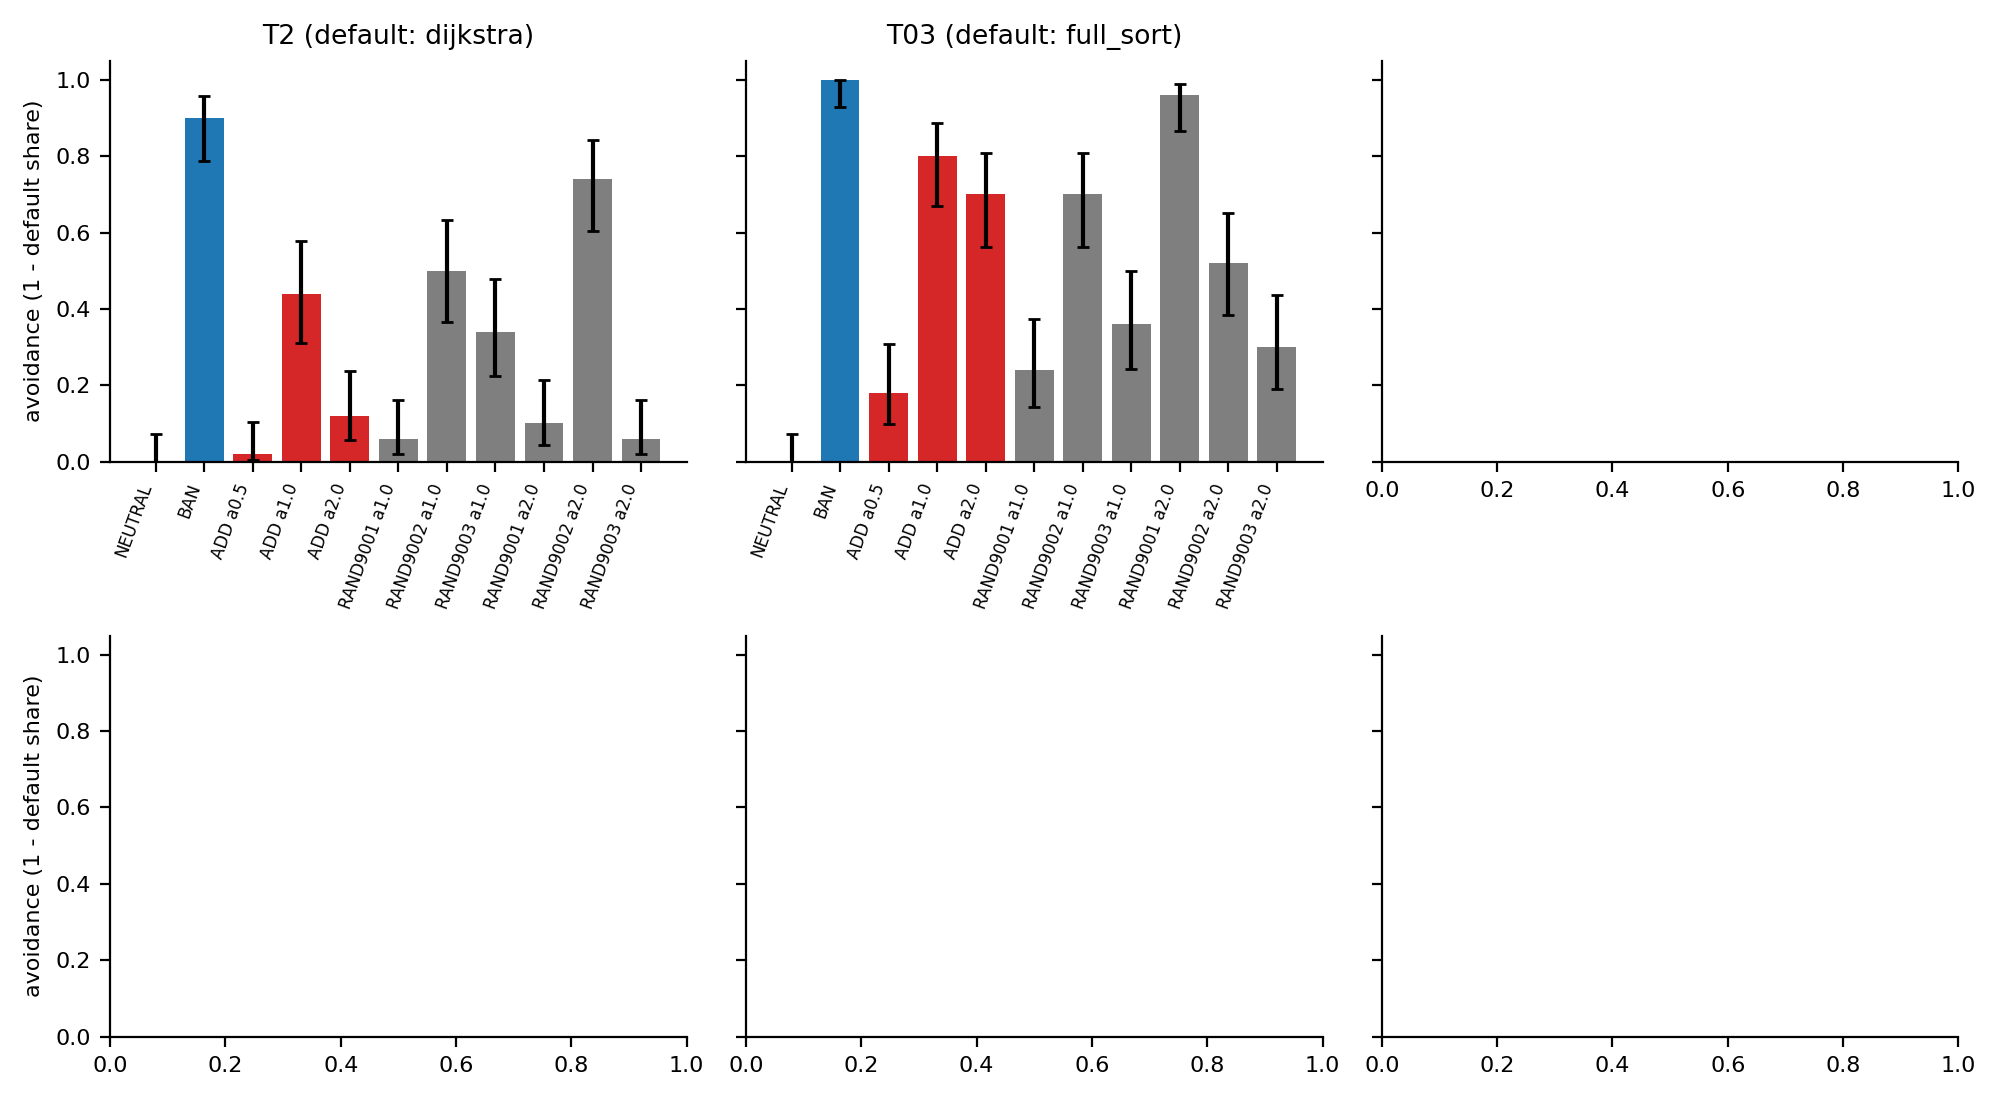

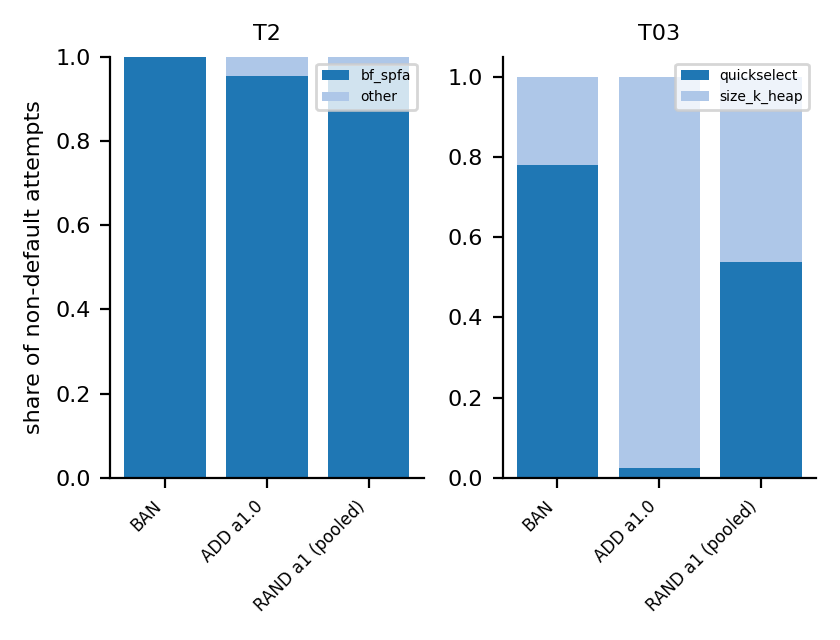

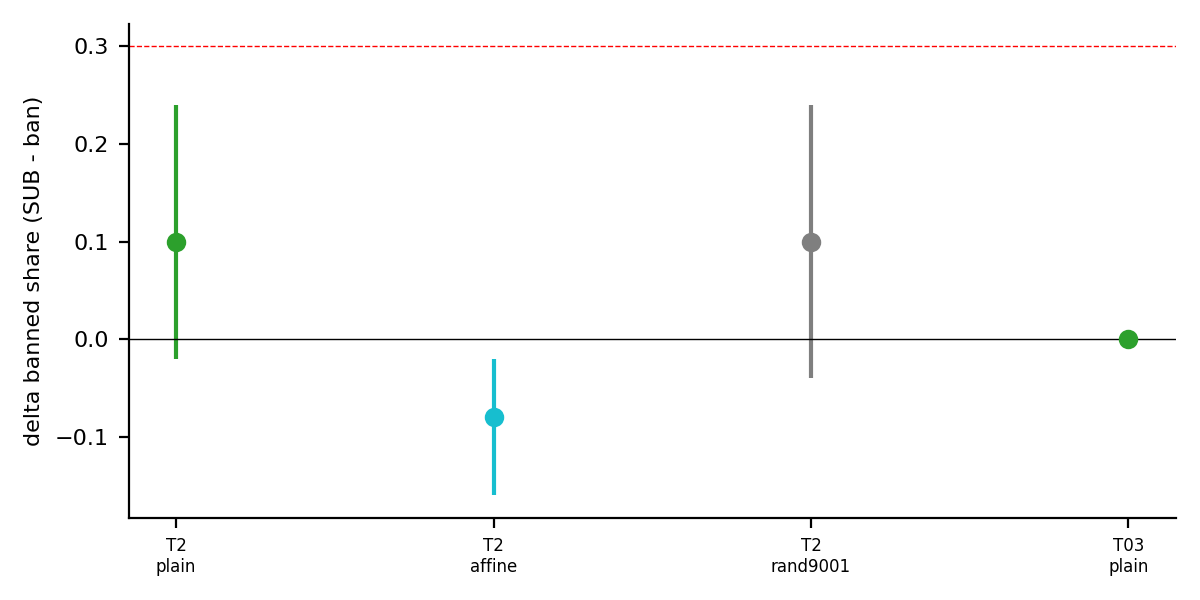

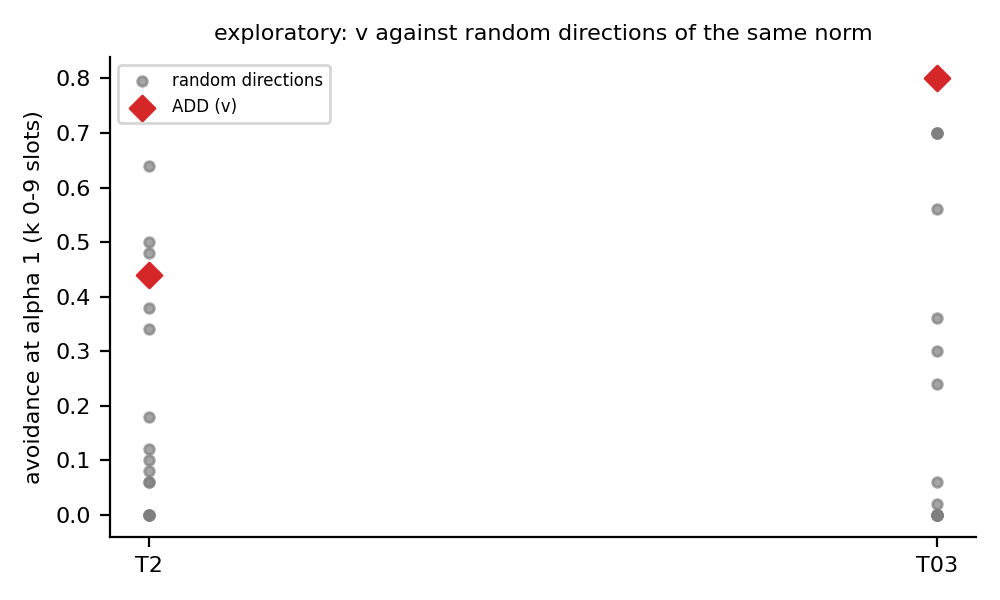

In [19]:
made = figures(c2d, None, {}, None, None)  # c2e / c2f / sae / manifold results are not part of the demo data
print("rendered:", made)
for name in made:
    display(Image(filename=str(FIG_DIR / f"{name}.png")))

## 4. Results

### Recomputed vs reported

The table below sets the C2d numbers recomputed above (demo subset) beside the values the artifact reported from its full run (in brackets; from `metadata.c2d` and `metadata.exploratory_random_distribution`).

- **Exact match expected (at `N_SLOTS = 10`):** the arms that were only ever sampled on slots k 0–9, i.e. ADD α 0.5 and α 2 and every RAND seed. The same holds for ADD α 1 restricted to k 0–9, as in the exploratory analysis. The cell checks this directly.
- **Small differences possible:** BAN, NEUTRAL and SUB_plain, which the full run sampled on k 0–19.

The verdict lines compare the demo subset's C2d verdict with the full six-task verdict.

In [20]:
rep = data["metadata"]["c2d"]                                  # reported: full run, 6 tasks, all slots
rep_erd = data["metadata"]["exploratory_random_distribution"]  # reported: exploratory, k 0-9 slots
nan = float("nan")


def f2(x, signed=False):
    return "-" if x is None else (f"{x:+.2f}" if signed else f"{x:.2f}")


recs = {}
for t, v in c2d["per_task"].items():
    a, ra = v["arms"], rep["per_task_add"][t]["avoidance"]
    av = lambda arm: a.get(arm, {}).get("avoidance", nan)
    erd, rerd = c2d["exploratory_random_distribution"].get(t, {}), rep_erd.get(t, {})
    sp, js = v["subtract"].get("SUB_plain"), v.get("js_add_vs_ban", {})
    recs[f"{t} (default {DEFAULT[t]})"] = {
        "BAN avoidance": f"{f2(av('BAN'))} ({f2(ra.get('BAN'))})",
        "NEUTRAL avoidance": f"{f2(av('NEUTRAL'))} ({f2(ra.get('NEUTRAL'))})",
        "BAN lands on": a.get("BAN", {}).get("modal_nondefault"),
        "ADD a1 avoidance, k 0-9": f"{f2(erd.get('add_avoidance_k0_9'))} ({f2(rerd.get('add_avoidance_k0_9'))})",
        "ADD a2 avoidance": f"{f2(av('ADD_a2.0'))} ({f2(ra.get('ADD_a2.0'))})",
        "RAND a1 avoidance, seeds 9001/9002/9003": " / ".join(f2(av(f"RAND{s}_a1.0")) for s in RAND_SEEDS),
        "ADD a1 lands on": a.get("ADD_a1.0", {}).get("modal_nondefault"),
        "JS(ADD, BAN landings) vs null q95": f"{f2(js.get('js'))} vs {f2(js.get('null_q95'))}",
        "event gate passed": v["event_gate"]["pass"],
        "ADD passes the frozen test": v["add_pass"],
        "ADD within the random range": v["add_within_random_range"],
        "SUB_plain delta banned share [95% CI]": (f"{f2(sp['delta_banned_share'], True)} [{f2(sp['ci95'][0], True)}, "
                                                  f"{f2(sp['ci95'][1], True)}]" if sp else "-"),
        "ADD percentile among 15 random dirs": (f"{f2(erd.get('add_percentile_among_random'))} "
                                                f"({f2(rerd.get('add_percentile_among_random'))})"),
    }
    k09 = [x for x in a if x.startswith("RAND") or x in ("ADD_a0.5", "ADD_a2.0")]  # arms sampled only on k 0-9
    diff = max(abs(av(x) - ra[x]) for x in k09 if x in ra)
    print(f"{t}: max |recomputed - reported| avoidance over the {len(k09)} arms sampled only on k 0-9 = {diff:.3f}")
print("(in brackets: reported by the artifact's full run)")
display(pd.DataFrame(recs))

pdm, prp = c2d["pooled_subtract"], rep["pooled_subtract"]
print(f"C2d verdict, recomputed on the demo subset {list(c2d['per_task'])}: {c2d['verdict']} -- ADD passes on "
      f"{c2d['n_add_pass']} of the gated tasks {c2d['denominator_tasks']}, within the random range on "
      f"{c2d['tasks_add_within_random_range']}")
print(f"C2d verdict, reported for the full run (6 tasks): {rep['verdict']} -- ADD passes on {rep['n_add_pass']} of the "
      f"gated tasks {rep['denominator_tasks']}, within the random range on {rep['within_random_range']}")
print(f"Pooled SUBTRACT delta: demo {pdm['tasks']} {f2(pdm['delta'], True)} CI {[round(c, 3) for c in pdm.get('ci95_task_bootstrap') or []]}; "
      f"reported {prp['tasks']} {f2(prp['delta'], True)} CI {[round(c, 3) for c in prp['ci95_task_bootstrap']]} "
      f"(the rule needs >= +0.3 with CI > 0)")

T2: max |recomputed - reported| avoidance over the 20 arms sampled only on k 0-9 = 0.000
T03: max |recomputed - reported| avoidance over the 20 arms sampled only on k 0-9 = 0.000
(in brackets: reported by the artifact's full run)


,T2 (default dijkstra),T03 (default full_sort)
BAN avoidance,0.90 (0.88),1.00 (1.00)
NEUTRAL avoidance,0.00 (0.00),0.00 (0.01)
BAN lands on,bf_spfa,quickselect
"ADD a1 avoidance, k 0-9",0.44 (0.44),0.80 (0.80)
ADD a2 avoidance,0.12 (0.12),0.70 (0.70)
"RAND a1 avoidance, seeds 9001/9002/9003",0.06 / 0.50 / 0.34,0.24 / 0.70 / 0.36
ADD a1 lands on,bf_spfa,size_k_heap
"JS(ADD, BAN landings) vs null q95",0.02 vs 0.02,0.51 vs 0.03
event gate passed,True,True
ADD passes the frozen test,False,False


C2d verdict, recomputed on the demo subset ['T2', 'T03']: DISCONFIRMED -- ADD passes on 0 of the gated tasks ['T2', 'T03'], within the random range on ['T2']
C2d verdict, reported for the full run (6 tasks): DISCONFIRMED -- ADD passes on 0 of the gated tasks ['T2', 'T1', 'T03', 'T06', 'T05'], within the random range on ['T2', 'T1', 'T04', 'T06', 'T05']
Pooled SUBTRACT delta: demo ['T2', 'T03'] +0.05 CI [0.0, 0.1]; reported ['T2', 'T1', 'T03', 'T06', 'T05'] -0.03 CI [-0.07, 0.028] (the rule needs >= +0.3 with CI > 0)


### The whole experiment at a glance

**Left panel:** the reported avoidance of every core arm on all six tasks (full run).

- ADD moves behaviour only on T2 and T03.
- Where ADD does move it, random directions of the same norm can move it as much (T2: seed 9002).
- SUB_plain, the ban with `v` projected out, keeps avoidance near the ban's level: removing `v` never brings back the default.

**Right panel:** the dose-response recomputed on the demo tasks. It is non-monotone in α, and individual random seeds overtake ADD at α 2.

Below the plot, the verdicts of the other three claims are printed from the reported metadata. The demo data cannot recompute them, because they need GPU-extracted states, head-ablation samples or SAE splices:

- **C2e:** no locus on any testable task.
- **C2f:** NOT SUPPORTED.
- **0g:** the frozen rule passes, but the rule is lenient.

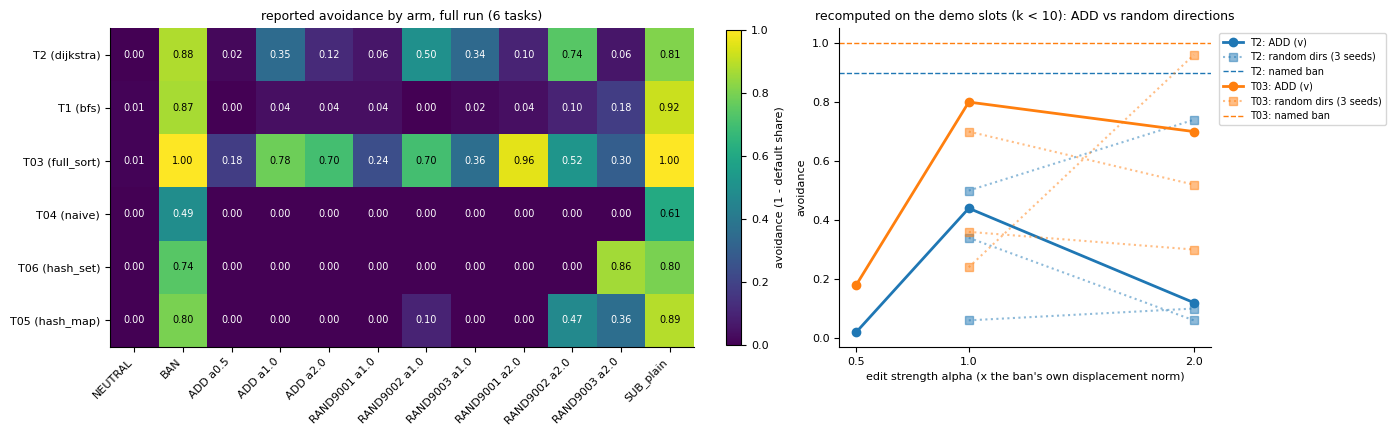

C2e within-ban locus (reported): {'T2': ('testable', None), 'T1': ('testable', None), 'T03': ('not testable (< 8 per class)', None), 'T04': ('testable', None), 'T06': ('testable', None), 'T05': ('testable', None)}
C2f head ablation (reported): NOT SUPPORTED -- delta_T1 = +0.06, delta_T2 = -0.03 (rule: T1 >= +0.15 over random heads and T2 unchanged)
0g Qwen-Scope SAE transfer (reported), frozen rule FR_zero(instruct) >= 0.9 x FR_zero(base):


,FR_zero instruct / own text,FR_zero base / own text,frozen rule pass
L15,0.988995,0.99285,True
L20,0.990341,0.990551,True
L27,0.993878,0.990705,True


In [21]:
%matplotlib inline
# (a) reported avoidance of the core arms on all six tasks (full run)
core = ["NEUTRAL", "BAN", "ADD_a0.5", "ADD_a1.0", "ADD_a2.0", "RAND9001_a1.0", "RAND9002_a1.0", "RAND9003_a1.0",
        "RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0", "SUB_plain"]
all_tasks = list(rep["per_task_add"])
M = np.array([[rep["per_task_add"][t]["avoidance"].get(a, np.nan) for a in core] for t in all_tasks], float)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.7, 1]})
im = ax1.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if np.isfinite(M[i, j]):
            ax1.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if M[i, j] < 0.6 else "k")
ax1.set_xticks(range(len(core)))
ax1.set_xticklabels([a.replace("_a", " a") for a in core], rotation=45, ha="right", fontsize=8)
ax1.set_yticks(range(len(all_tasks)))
ax1.set_yticklabels([f"{t} ({DEFAULT[t]})" for t in all_tasks], fontsize=8)
ax1.set_title("reported avoidance by arm, full run (6 tasks)", fontsize=9)
fig.colorbar(im, ax=ax1, fraction=0.025, label="avoidance (1 - default share)")
# (b) recomputed dose-response on the demo tasks: ADD (v) against the three frozen random directions
for i, (t, v) in enumerate(c2d["per_task"].items()):
    c = f"C{i}"
    ax2.plot([0.5, 1.0, 2.0], [v["arms"].get(f"ADD_a{al}", {}).get("avoidance", np.nan) for al in (0.5, 1.0, 2.0)],
             "o-", color=c, lw=2, label=f"{t}: ADD (v)")
    for s in RAND_SEEDS:
        ax2.plot([1.0, 2.0], [v["arms"].get(f"RAND{s}_a{al}", {}).get("avoidance", np.nan) for al in (1.0, 2.0)],
                 "s:", color=c, alpha=0.5, label=f"{t}: random dirs (3 seeds)" if s == RAND_SEEDS[0] else None)
    ax2.axhline(v["arms"]["BAN"]["avoidance"], color=c, ls="--", lw=1, label=f"{t}: named ban")
ax2.set_xticks([0.5, 1.0, 2.0])
ax2.set_xlabel("edit strength alpha (x the ban's own displacement norm)")
ax2.set_ylabel("avoidance")
ax2.set_ylim(-0.03, 1.05)
ax2.set_title(f"recomputed on the demo slots (k < {N_SLOTS}): ADD vs random directions", fontsize=9)
ax2.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

# the other three claims need GPU states, head-ablation samples or SAE splices: reported values
m = data["metadata"]
print("C2e within-ban locus (reported):", {t: (v["status"], v["locus"]) for t, v in m["c2e"].items()})
print(f"C2f head ablation (reported): {m['c2f']['verdict']} -- delta_T1 = {m['c2f']['delta_T1']:+.2f}, "
      f"delta_T2 = {m['c2f']['delta_T2']:+.2f} (rule: T1 >= +0.15 over random heads and T2 unchanged)")
print("0g Qwen-Scope SAE transfer (reported), frozen rule FR_zero(instruct) >= 0.9 x FR_zero(base):")
display(pd.DataFrame({f"L{L}": {"FR_zero instruct / own text": z["fr_zero_inst_own"],
                                "FR_zero base / own text": z["fr_zero_base_own"], "frozen rule pass": z["frozen_pass"]}
                      for L, z in m["zero_g"]["per_layer"].items()}).T)